# Scalar-induced gravitational waves for a general equation of state

Updated implementation notes:

- The scalar transfer function is stored as the Newtonian potential per unit curvature perturbation, so the primordial spectrum functions below should return `P_zeta(k)`.
- `Phi_mat_*` and `Phi_prime_mat_*` are saved in separate chunks. `Phi_prime` is the conformal-time derivative `dPhi/deta`, matching the source term.
- The tensor Green function is built for the variable `g = a h`, following the form used in arXiv:2307.01653.
- Heavy precomputation cells are guarded by flags. Set them to `True` only when you want to regenerate the transfer/function or kernel cache.


In [1]:
# for latex rendering


import matplotlib as mpl
import matplotlib.pyplot as plt
plt.rcParams['savefig.dpi'] = 75
mpl.rcParams.update({'font.size': 22, 'font.family': 'serif'})
plt.rcParams['figure.autolayout'] = False
plt.rcParams['figure.figsize'] = 10, 6 #6.4, 4.8
plt.rcParams['axes.labelsize'] = 18
plt.rcParams['axes.titlesize'] = 20
plt.rcParams['font.size'] = 16
plt.rcParams['lines.linewidth'] = 2.0
plt.rcParams['lines.markersize'] = 8
plt.rcParams['legend.fontsize'] = 15
mpl.rc('axes',edgecolor='k')
plt.rcParams['xtick.color'] = 'k'
plt.rcParams['ytick.color'] = 'k'
plt.rcParams["axes.axisbelow"] = False
plt.rcParams["xtick.major.size"] = 6
plt.rcParams["xtick.minor.size"] = 3
plt.rcParams["ytick.major.size"] = 6
plt.rcParams["ytick.minor.size"] = 3
plt.rcParams['xtick.direction'] = 'in'
plt.rcParams['ytick.direction'] = 'in'
plt.rcParams['text.usetex'] = True 
colors = plt.get_cmap('tab10')


In [ ]:
from pathlib import Path
import sys
from dataclasses import dataclass
from concurrent.futures import ThreadPoolExecutor
import json
import math
import warnings

import numpy as np
from scipy.integrate import simpson, solve_ivp, trapezoid
from scipy.optimize import minimize_scalar
from scipy.interpolate import CubicHermiteSpline, CubicSpline, RectBivariateSpline, RegularGridInterpolator
from numpy.polynomial.legendre import leggauss
import matplotlib.pyplot as plt

# Robust project discovery. This lets the notebook run whether Jupyter was
# started in SIGW_eos, in its parent, or from this exact desktop project path.
PROJECT_CANDIDATES = [
    Path.cwd(),
    Path.cwd() / 'sigw' / 'SIGW_EOS' / 'SIGW_EOS',
    Path.cwd().parent,
    Path('D:\My_work\92_real_IGW_at_PTA\sigw\SIGW_EOS\SIGW_EOS'),
]
PROJECT_DIR = next((p.resolve() for p in PROJECT_CANDIDATES
                    if (p / 'SIGW_EoS_QCD.ipynb').exists()
                    and (p / 'transferfunction').exists()), None)
if PROJECT_DIR is None:
    raise FileNotFoundError('Could not find the QCD notebook and transferfunction/ folder. Update PROJECT_DIR manually.')

if str(PROJECT_DIR) not in sys.path:
    sys.path.insert(0, str(PROJECT_DIR))
from thermal_background import (load_thermal_eos, thermal_eos_value,
                                solve_thermal_background_from_highT, background_values)

TRANSFER_DIR = PROJECT_DIR / 'transferfunction'
DATA_DIR = PROJECT_DIR / 'data'
# Physical high-temperature boundary changes every downstream transfer cache.
CACHE_CASE = 'QCD_adiabatic_highT'
import hashlib
_BACKGROUND_SOURCE_DIGEST = hashlib.sha256()
for _path in (TRANSFER_DIR / 'omega2_new_merged.csv',
              TRANSFER_DIR / 'cs2_new_merged.csv',
              PROJECT_DIR / 'thermal_background.py'):
    _BACKGROUND_SOURCE_DIGEST.update(_path.read_bytes())
BACKGROUND_SOURCE_SHA256 = _BACKGROUND_SOURCE_DIGEST.hexdigest()

TENSOR_INCLUDE_W_CORRECTION = True
CACHE_DIR = DATA_DIR / CACHE_CASE
PHI_CACHE_DIR = CACHE_DIR / 'phi'
GREEN_CACHE_DIR = CACHE_DIR / 'green'
KERNEL_CACHE_DIR = CACHE_DIR / 'kernel'
for directory in (DATA_DIR, CACHE_DIR, PHI_CACHE_DIR, GREEN_CACHE_DIR, KERNEL_CACHE_DIR):
    directory.mkdir(parents=True, exist_ok=True)

print('PROJECT_DIR =', PROJECT_DIR)
print('TRANSFER_DIR =', TRANSFER_DIR)


PROJECT_DIR = C:\Research\92_real_IGW_at_PTA\sigw\SIGW_EOS\SIGW_EOS
TRANSFER_DIR = C:\Research\92_real_IGW_at_PTA\sigw\SIGW_EOS\SIGW_EOS\transferfunction


## Background functions

The input tables are the merged `omega2_new_merged.csv` and `cs2_new_merged.csv` files in legacy C/T coordinates. The thermal background solves T(eta) self-consistently using the supplied w(T) and c_s^2(T), following SIGW_EoS_model.ipynb. Outside the tabulated temperature range, radiation values are used with continuous radiation extensions.


In [3]:
RADIATION_W = 1.0 / 3.0
OMEGA_R0_H2 = 4.2e-5
SPEED_OF_LIGHT_M_S = 299_792_458.0
MPC_METERS = 3.085677581491367e22
K_MPC_TO_HZ = SPEED_OF_LIGHT_M_S / (2.0 * np.pi * MPC_METERS)


def k_mpc_to_hz(k_mpc):
    """Convert comoving k in Mpc^-1 to cyclic frequency in Hz today."""
    return np.asarray(k_mpc, dtype=float) * K_MPC_TO_HZ


def hz_to_k_mpc(f_hz):
    """Convert cyclic frequency in Hz to comoving k in Mpc^-1."""
    return np.asarray(f_hz, dtype=float) / K_MPC_TO_HZ


eta0 = 1.0  # Mpc
h = 675/1000
Omega_r = 247*1e-7/h**2
Omega_v = 3 * 7 / 8 * (4/11)**(4/3) * Omega_r
a0 = h/(3e+3) * (Omega_r+Omega_v)**.5 * eta0  # a0 = H0 * Sqrt[Omega_r+Omega_v] * eta0
T0 = 2.73 * 8.6 * 1e-11 / a0 * (3.94/10)**(1/3)  # MeV  
Mpl = 2.4353 * 1e+21 # MeV

# The CSV first column is the legacy C/T coordinate, NOT physical eta.
DIRECT_ETA_T_CONSTANT = T0 * eta0  # MeV Mpc; preserve the existing early T scale.
THERMAL_EOS = load_thermal_eos(TRANSFER_DIR / 'omega2_new_merged.csv',
                               TRANSFER_DIR / 'cs2_new_merged.csv', DIRECT_ETA_T_CONSTANT)
data_w = THERMAL_EOS['w_table']
data_cs = THERMAL_EOS['cs2_table']


def eos_temperature(temperature):
    return thermal_eos_value(THERMAL_EOS, temperature, 'w')


def cs2_temperature(temperature):
    return thermal_eos_value(THERMAL_EOS, temperature, 'cs2')


# Physical high-temperature radiation boundary: g_rho=g_s=106.75.
# T_high is above the merged SM table (which ends at 1e6 MeV).
T0_PHYSICAL_MEV = 2.73 * 8.6e-11
HIGH_T_MEV = 1e9
HIGH_G_RHO = HIGH_G_S = 106.75
BACKGROUND_SETTINGS = dict(
    T_high=HIGH_T_MEV, g_rho_high=HIGH_G_RHO, g_s_high=HIGH_G_S,
    T0_physical=T0_PHYSICAL_MEV, g_s0=3.94, Mpl_MeV=Mpl,
    eta_max=1e1,
    n_points=14001, rtol=1e-10, atol=1e-12, max_step=0.05,
)
# eta(T_high)=1/[a_phys(T_high) H(T_high)] fixes the eta=0 origin.
background = solve_thermal_background_from_highT(
    eos_temperature, cs2_temperature, **BACKGROUND_SETTINGS)


def _background_values(eta):
    a_value, conH_value, _ = background_values(background, eta)
    return a_value, conH_value


def temperature_interp(eta):
    return background_values(background, eta)[2]


def eos(eta):
    return eos_temperature(temperature_interp(eta))


def c_s_sq(eta):
    return cs2_temperature(temperature_interp(eta))


def cs2_prime(eta):
    # Chain rule: dcs2/deta = dcs2/dlnT * (-3 calH cs2).
    temperature = temperature_interp(eta)
    return (thermal_eos_value(THERMAL_EOS, temperature, 'cs2', derivative=True)
            * (-3.0 * conH_interp(eta) * cs2_temperature(temperature)))


def a_interp(eta):
    return _background_values(eta)[0]


def conH_interp(eta):
    return _background_values(eta)[1]


def aprime_interp(eta):
    return a_interp(eta) * conH_interp(eta)


def a_doubleprime_over_a(eta):
    return 0.5 * (1.0 - 3.0 * eos(eta)) * conH_interp(eta)**2


def a_doubleprime_interp(eta):
    return a_interp(eta) * a_doubleprime_over_a(eta)


def conHprime(eta):
    return -0.5 * (1.0 + 3.0 * eos(eta)) * conH_interp(eta)**2


def conHprime_interp(eta):
    return conHprime(eta)


H_min_eta, H_max_eta = background['eta_min'], background['eta_max']
a_min_eta, a_max_eta = H_min_eta, H_max_eta
# Actual conformal-time limits of the temperature tables, for diagnostics.
_log_eta_at_table_T = np.interp(
    THERMAL_EOS['log_temperature'],
    np.log(background['temperature'])[::-1], background['log_eta'][::-1])
w_min_eta, w_max_eta = np.exp(_log_eta_at_table_T[[ -1, 0]])
cs_min_eta, cs_max_eta = w_min_eta, w_max_eta
(CACHE_DIR / 'background_metadata.json').write_text(json.dumps(dict(
    fingerprint=BACKGROUND_SOURCE_SHA256, settings=BACKGROUND_SETTINGS,
    temperature_constant_MeV_Mpc=DIRECT_ETA_T_CONSTANT,
    table_coordinate='C/T (legacy coordinate, not physical eta)',
    eta_boundary_Mpc=background['high_eta'],
    a_phys_boundary=background['high_a_phys'],
    H_boundary_Mpc_inv=background['high_H_Mpc'],
    calibration='physical a(T_high), H(T_high), eta=1/(aH); a_today=1',
), indent=2))


def tensor_mass_over_k2(eta, k, include_w_correction=None):
    # From Lambda_eta = d_eta^2 + k^2 - (1 - 3w) calH^2 / 2.
    # This switch affects tensor propagation only.  The scalar Phi
    # equation below continues to use the self-consistent eos(eta).
    h_over_k = conH_interp(eta) / k
    if include_w_correction is None:
        include_w_correction = TENSOR_INCLUDE_W_CORRECTION
    if not include_w_correction:
        return np.zeros_like(h_over_k, dtype=float)
    return 0.5 * (1.0 - 3.0 * eos(eta)) * h_over_k**2


def today_redshift_factor(eta_c, eta_f=None, omega_r0_h2=OMEGA_R0_H2):
    # Eq. (OGWh2) of arXiv:2307.01653. eta_f should be after the relevant
    # phase transitions. The end of Htau.csv is a conservative default.
    if eta_f is None:
        eta_f = H_max_eta
    numerator = a_interp(eta_c) * conH_interp(eta_c)
    denominator = a_interp(eta_f) * conH_interp(eta_f)
    return omega_r0_h2 * (numerator / denominator)**2

print('w eta range:', w_min_eta, w_max_eta)
print('cs2 eta range:', cs_min_eta, cs_max_eta)
print('a eta range:', a_min_eta, a_max_eta)
print('H eta range:', H_min_eta, H_max_eta)


w eta range: 5.822890496810032e-11 0.009096607147755545
cs2 eta range: 5.822890496810032e-11 0.009096607147755545
a eta range: 5.822890496878071e-14 10.0
H eta range: 5.822890496878071e-14 10.0


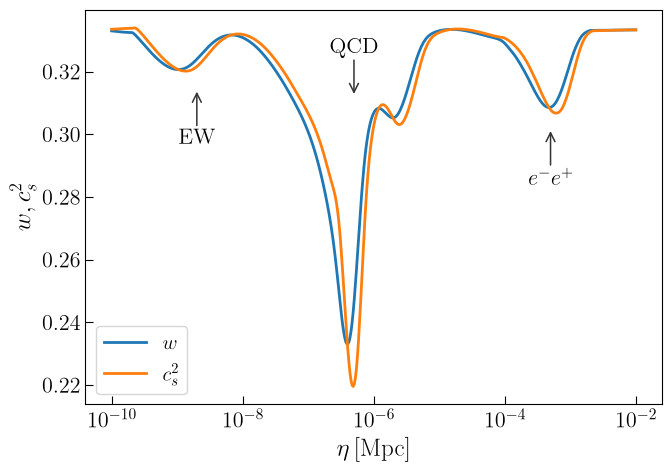

In [54]:
# Quick background sanity plot.
eta_plot = np.geomspace(1e-10, 1e-2, 500)
fig, ax = plt.subplots(figsize=(7, 5))
ax.plot(eta_plot, eos(eta_plot), label=r'$w$')
ax.plot(eta_plot, c_s_sq(eta_plot), label=r'$c_s^2$')
ax.set_xscale('log')
ax.set_xlabel(r'$\eta\,[\mathrm{Mpc}]$')

# Each label can be moved independently in axes-fraction y coordinates.
ew_text_y = 0.7
qcd_text_y = 0.88
electron_text_y = 0.6
transition_eta = {
    'EW': 2e-9,
    'QCD': 5e-7,
    'e-e+': 5e-4,
}
arrow_length = 0.10
arrow_style = dict(
    arrowstyle='->', color='0.2', lw=1.1,
    shrinkA=0, shrinkB=2,
)

# EW and e-e+ point upward; QCD points downward.
for label, eta_target, text_y in (
    ('EW', transition_eta['EW'], ew_text_y),
    (r'$e^-e^+$', transition_eta['e-e+'], electron_text_y),
):
    ax.annotate(
        label,
        xy=(eta_target, text_y + arrow_length),
        xycoords=('data', 'axes fraction'),
        xytext=(eta_target, text_y),
        textcoords=('data', 'axes fraction'),
        ha='center', va='top', arrowprops=arrow_style,
    )
ax.annotate(
    'QCD',
    xy=(transition_eta['QCD'], qcd_text_y - arrow_length),
    xycoords=('data', 'axes fraction'),
    xytext=(transition_eta['QCD'], qcd_text_y),
    textcoords=('data', 'axes fraction'),
    ha='center', va='bottom', arrowprops=arrow_style,
)

ax.legend()
plt.ylabel(r'$w, c_s^2$')
fig.tight_layout()

plt.savefig('plot/PT_QCD_text.pdf')
if '__file__' not in globals():
    plt.show()
else:
    plt.close()


## Scalar transfer function `Phi`

The Bardeen equation is implemented in the form used in arXiv:2307.01653,

\[
\Phi_k''+3\mathcal{H}(1+c_s^2)\Phi_k'
+\left[c_s^2 k^2+3\mathcal{H}^2(c_s^2-w)\right]\Phi_k=0.
\]

The ODE is solved in the dimensionless variable `x = k eta`, which is faster and numerically better scaled. At `x_ini`, the decaying mode is removed and the growing superhorizon solution $\Phi=-A(\eta)$ is used, with $A=1-\mathcal{H}a^{-2}\int_0^\eta a^2d\tilde\eta$. The saved `Phi_prime_mat_*` remains `dPhi/deta`.


In [5]:
X_INI = 1e-3
X_FINAL = 1e3
N_X_DEFAULT = 8000
PHI_X_SWITCH = 30.0
PHI_RTOL = 3e-8
PHI_ATOL = 1e-10
PHI_INITIAL_CONDITION = 'analytic_superhorizon_v1' # analytic_superhorizon_v1 or pure_radiation

def phi_x_grid(x_ini, x_final, n_points, x_switch=PHI_X_SWITCH):
    """Resolve early evolution logarithmically and late oscillations linearly."""
    x_ini = float(x_ini)
    x_final = float(x_final)
    n_points = int(n_points)
    x_switch = float(x_switch)
    if not (0.0 < x_ini < x_switch < x_final) or n_points < 512:
        raise ValueError('Require 0 < x_ini < x_switch < x_final and n_points >= 512.')
    n_log = max(256, n_points // 5)
    n_linear = n_points - n_log + 1
    return np.concatenate((
        np.geomspace(x_ini, x_switch, n_log)[:-1],
        np.linspace(x_switch, x_final, n_linear),
    ))

@dataclass(frozen=True)
class TransferChunk:
    label: str
    k_min: float
    k_max: float
    n_k: int


PHI_CHUNKS = [
    # Extend to 1e-2--1e16 Mpc^-1 without changing existing chunk grids.
    TransferChunk('-20', 1e-2, 1e0, 120),
    TransferChunk('02', 1e0, 1e2, 120),
    TransferChunk('24', 1e2, 1e4, 200),
    TransferChunk('46', 1e4, 1e6, 200),
    TransferChunk('68', 1e6, 1e8, 200),
    TransferChunk('810', 1e8, 1e10, 200),
    TransferChunk('1014', 1e10, 1e14, 400),
    TransferChunk('1416', 1e14, 1e16, 200),
]


def phi_rhs_x(x, y, k):
    phi, dphi_dx = y
    eta = x / k
    h_over_k = conH_interp(eta) / k
    cs2 = c_s_sq(eta)
    w = eos(eta)
    d2phi_dx2 = -3.0 * (1.0 + cs2) * h_over_k * dphi_dx - (cs2 + 3.0 * h_over_k**2 * (cs2 - w)) * phi
    return [dphi_dx, d2phi_dx2]


def _superhorizon_integral(eta, n_points=4096):
    """Numerically evaluate integral_0^eta a(eta')^2 d eta'."""
    eta = float(eta)
    eta_grid = np.geomspace(eta / 1e4, eta, int(n_points))
    return trapezoid(a_interp(eta_grid)**2, eta_grid)


def superhorizon_mode(eta):
    """Growing adiabatic superhorizon mode A(eta), with decay mode removed."""
    eta = float(eta)
    integral = _superhorizon_integral(eta)
    return 1.0 - conH_interp(eta) * integral / a_interp(eta)**2


def superhorizon_mode_prime(eta):
    """Conformal-time derivative of the growing superhorizon mode."""
    eta = float(eta)
    integral_over_a2 = _superhorizon_integral(eta) / a_interp(eta)**2
    H = conH_interp(eta)
    return -(conHprime_interp(eta) - 2.0 * H**2) * integral_over_a2 - H


def solve_phi_transfer(
    k,
    x_grid=None,
    rtol=PHI_RTOL,
    atol=PHI_ATOL,
    initial_condition=PHI_INITIAL_CONDITION,
):
    if x_grid is None:
        x_grid = phi_x_grid(X_INI, X_FINAL, N_X_DEFAULT)
    k = float(k)
    x0 = float(x_grid[0])
    eta0 = x0 / k
    if initial_condition == 'analytic_superhorizon_v1':
        # Growing superhorizon solution per unit zeta, as in SIGW_EoS.ipynb:
        # Phi=-A(eta), dPhi/dx=-A'(eta)/k; the decaying mode is set to zero.
        y0 = [-superhorizon_mode(eta0), -superhorizon_mode_prime(eta0) / k]
    elif initial_condition == 'pure_radiation':
        # Radiation-era analytic solution at x_ini=k*eta_ini.
        y0 = [-2.0 / 3.0 * (1.0 - x0**2 / 30.0), 2.0 * x0 / 45.0]
    else:
        raise ValueError(
            f"initial_condition must be {PHI_INITIAL_CONDITION!r} or 'pure_radiation'"
        )
    sol = solve_ivp(
        phi_rhs_x,
        (float(x_grid[0]), float(x_grid[-1])),
        y0,
        t_eval=x_grid,
        args=(k,),
        method='DOP853',
        rtol=rtol,
        atol=atol,
    )
    if not sol.success:
        raise RuntimeError(f'Phi solver failed for k={k:.6g}: {sol.message}')
    phi = sol.y[0]
    phi_prime_eta = k * sol.y[1]
    return phi, phi_prime_eta


def _chunk_paths(chunk, directory=PHI_CACHE_DIR):
    return {
        'phi': directory / f'Phi_mat_{chunk.label}.npy',
        'phi_prime': directory / f'Phi_prime_mat_{chunk.label}.npy',
        'meta': directory / f'Phi_meta_{chunk.label}.json',
    }


def _phi_cache_compatible(chunk, directory=PHI_CACHE_DIR, n_x=N_X_DEFAULT):
    paths = _chunk_paths(chunk, directory=directory)
    if not (paths['phi'].exists() and paths['phi_prime'].exists() and paths['meta'].exists()):
        return False
    try:
        meta = json.loads(paths['meta'].read_text())
    except (OSError, json.JSONDecodeError):
        return False
    return (
        meta.get('label') == chunk.label
        and np.isclose(float(meta.get('k_min')), chunk.k_min)
        and np.isclose(float(meta.get('k_max')), chunk.k_max)
        and int(meta.get('n_k')) == int(chunk.n_k)
        and np.isclose(float(meta.get('x_ini')), X_INI)
        and np.isclose(float(meta.get('x_final')), X_FINAL)
        and int(meta.get('n_x')) == int(n_x)
        and meta.get('x_grid', 'geometric') in {'geometric', 'log_linear'}
        and meta.get('initial_condition') == PHI_INITIAL_CONDITION
    )


def save_phi_chunk(chunk, n_x=N_X_DEFAULT, overwrite=False):
    paths = _chunk_paths(chunk)
    cache_exists = paths['phi'].exists() and paths['phi_prime'].exists()
    if not overwrite and cache_exists and _phi_cache_compatible(chunk, n_x=n_x):
        print(f'Phi chunk {chunk.label} already exists with initial_condition={PHI_INITIAL_CONDITION}; reusing it')
        return
    if cache_exists and not _phi_cache_compatible(chunk, n_x=n_x):
        print(f'Phi chunk {chunk.label} has incompatible metadata; regenerating it')
    x_grid = phi_x_grid(X_INI, X_FINAL, int(n_x))
    k_grid = np.geomspace(chunk.k_min, chunk.k_max, chunk.n_k)
    phi_mat = np.empty((chunk.n_k, int(n_x)), dtype=np.float64)
    phi_prime_mat = np.empty_like(phi_mat)
    for i, k in enumerate(k_grid, start=1):
        phi_mat[i - 1], phi_prime_mat[i - 1] = solve_phi_transfer(k, x_grid=x_grid)
        if i == 1 or i == chunk.n_k or i % max(1, chunk.n_k // 20) == 0:
            print(f'Phi {chunk.label}: {i}/{chunk.n_k}')
    np.save(paths['phi'], phi_mat)
    np.save(paths['phi_prime'], phi_prime_mat)
    paths['meta'].write_text(json.dumps({
        'label': chunk.label,
        'k_min': chunk.k_min,
        'k_max': chunk.k_max,
        'n_k': chunk.n_k,
        'x_ini': X_INI,
        'x_final': X_FINAL,
        'n_x': int(n_x),
        'x_grid': 'log_linear',
        'phi_prime': 'dPhi/deta',
        'initial_condition': PHI_INITIAL_CONDITION,
        'normalization': (
            'Phi per unit zeta; pure-radiation analytic initial condition'
            if PHI_INITIAL_CONDITION == 'pure_radiation'
            else 'Phi per unit zeta; growing analytic superhorizon mode Phi=-A(eta), decaying mode removed'
        ),
    }, indent=2))


def phi_chunk_available(chunk):
    updated = _chunk_paths(chunk)
    original_phi = DATA_DIR / f'Phi_mat_{chunk.label}.npy'
    original_prime = DATA_DIR / f'Phi_prime_mat_{chunk.label}.npy'
    return (
        _phi_cache_compatible(chunk)
        or (original_phi.exists() and original_prime.exists())
    )


def generate_missing_phi_chunks(chunks=PHI_CHUNKS, n_x=N_X_DEFAULT):
    for chunk in chunks:
        save_phi_chunk(chunk, n_x=n_x, overwrite=False)


def default_kernel_log10s_grid():
    # Match the unique grid used by the original notebook.  The original
    # construction included the two segment joins twice and removed the
    # duplicates before building the 3-D interpolator.
    return np.r_[
        np.linspace(-2, -0.5, 10)[:-1],
        np.linspace(-0.5, 0.5, 50)[:-1],
        np.linspace(0.5, 2, 20),
    ]


def default_kernel_t_grid():
    # The original kernel files used t <= 0.7 (20 points).
    return np.linspace(0.0, 0.7, 20)


def scalar_k_range_for_kernel(k_grid, log10s_grid=None, t_grid=None):
    if log10s_grid is None:
        log10s_grid = default_kernel_log10s_grid()
    if t_grid is None:
        t_grid = default_kernel_t_grid()
    s_mesh, t_mesh = np.meshgrid(np.asarray(log10s_grid, dtype=float), np.asarray(t_grid, dtype=float), indexing='xy')
    u_mesh, v_mesh = st_to_uv(s_mesh, t_mesh)
    scalar_multiplier_min = float(np.nanmin([np.nanmin(u_mesh), np.nanmin(v_mesh)]))
    scalar_multiplier_max = float(np.nanmax([np.nanmax(u_mesh), np.nanmax(v_mesh)]))
    k_grid = np.asarray(k_grid, dtype=float)
    return float(np.nanmin(k_grid) * scalar_multiplier_min), float(np.nanmax(k_grid) * scalar_multiplier_max)


def required_phi_chunks_for_kernel(k_grid, log10s_grid=None, t_grid=None):
    scalar_k_min, scalar_k_max = scalar_k_range_for_kernel(k_grid, log10s_grid, t_grid)
    required = [chunk for chunk in PHI_CHUNKS if chunk.k_max >= scalar_k_min and chunk.k_min <= scalar_k_max]
    if not required or required[0].k_min > scalar_k_min or required[-1].k_max < scalar_k_max:
        raise ValueError(
            f'PHI_CHUNKS do not cover scalar k range [{scalar_k_min:.6g}, {scalar_k_max:.6g}] required by this kernel grid.'
        )
    return required


def ensure_phi_chunks_for_kernel(k_grid, log10s_grid=None, t_grid=None, n_x=N_X_DEFAULT):
    scalar_k_min, scalar_k_max = scalar_k_range_for_kernel(k_grid, log10s_grid, t_grid)
    required = required_phi_chunks_for_kernel(k_grid, log10s_grid, t_grid)
    missing = [chunk for chunk in required if not phi_chunk_available(chunk)]
    print(f'Kernel scalar transfer k range: [{scalar_k_min:.6g}, {scalar_k_max:.6g}]')
    if missing:
        print('Generating missing Phi chunks for kernel:', [chunk.label for chunk in missing])
        generate_missing_phi_chunks(missing, n_x=n_x)
    return scalar_k_min, scalar_k_max


In [6]:
def phi_ana(k, eta): # transfer function for Newtonian potential
    return -6/(k*eta)**2 * (np.sin(k*eta/np.sqrt(3))/(k*eta/np.sqrt(3)) - np.cos(k*eta/np.sqrt(3)))
def phi_p_ana(k, eta): # derivative for the transfer function
    return -2/(eta**4 * k**3) * (9*eta*k * np.cos(k*eta/np.sqrt(3)) + np.sqrt(3) * (-9+k**2 * eta**2)*np.sin(k*eta/np.sqrt(3)))


### Initial condition check

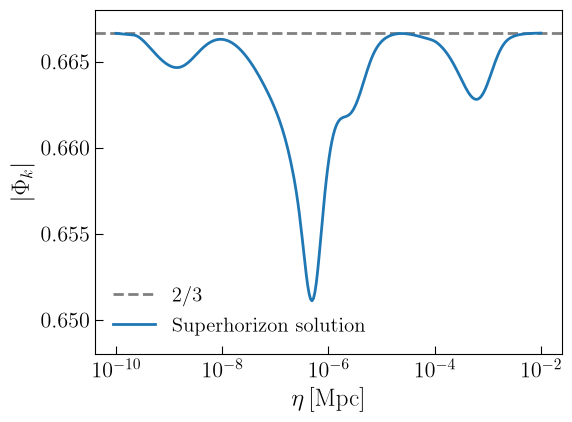

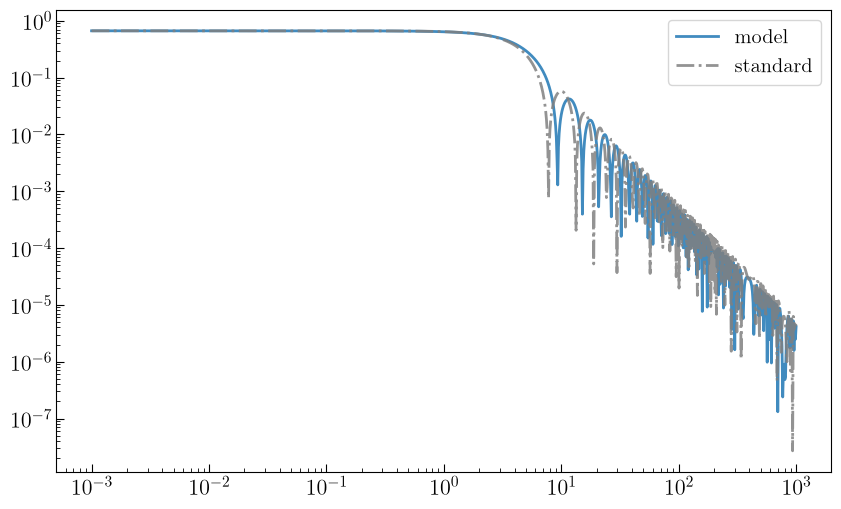

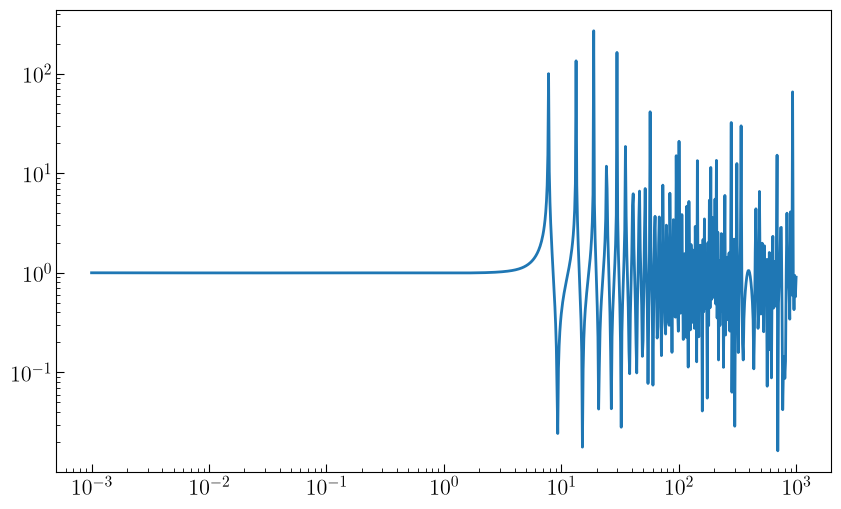

In [53]:
# This cell requires the updated solver definition above.  In a live Jupyter
# kernel, rerun that definition cell after editing the notebook.
import inspect
if 'initial_condition' not in inspect.signature(solve_phi_transfer).parameters:
    raise RuntimeError(
        'The kernel still has the old solve_phi_transfer definition. '
        'Rerun the Phi solver-definition cell above, then rerun this cell.'
    )

eta_span = np.geomspace(1e-10, 1e-2, 300)
superhorizon_fractional_shift = np.array([
    superhorizon_mode(eta)
    for eta in eta_span
])
plt.figure(figsize=(6, 4.5))
plt.axhline(2/3, color='gray', ls='--', label='2/3')
plt.plot(eta_span, superhorizon_fractional_shift, label='Superhorizon solution')
plt.xlabel(r'$\eta\,[\mathrm{Mpc}]$')
plt.xscale('log')
plt.ylabel(r'$|\Phi_k|$')
plt.ylim(0.648,0.668)
plt.legend(frameon=False)
plt.tight_layout()
plt.savefig('plot/superhorizon solution.pdf')
plt.show()

k_value = 1.2e7
comparison_x = np.geomspace(1e-3,1e+3,1000)
phi_radiation, _ = solve_phi_transfer(
        k_value, x_grid=comparison_x, initial_condition='pure_radiation'
)
plt.loglog(comparison_x, abs(phi_radiation),
              alpha=0.85, label='model')
plt.loglog(comparison_x, abs(phi_ana(k_value,comparison_x/k_value)), color = 'gray',alpha=0.85, ls='-.', label = 'standard')
plt.legend()
plt.show()

plt.loglog(comparison_x,abs(phi_radiation/phi_ana(k_value,comparison_x/k_value)))
#plt.xlim(1e-3,1e+0)


### WKB amplitude check
$$
    \Phi_k(\eta)\sim\frac{C_k}{\sqrt{k c_s(\eta)}}
    \exp\left[-\frac32\int^\eta\mathcal H(1+c_s^2)\,d\tilde\eta\right]
    \exp\left[\pm ik\int^\eta c_s(\tilde\eta)d\tilde\eta\right],
$$
Phase delay
$$
    \Delta\theta(k,\eta)-\Delta\theta(k,\eta_W)
    \simeq k\int_{\eta_W}^{\eta}
    \left[c_s(\tilde\eta)-\frac{1}{\sqrt{3}}\right]d\tilde\eta,
$$

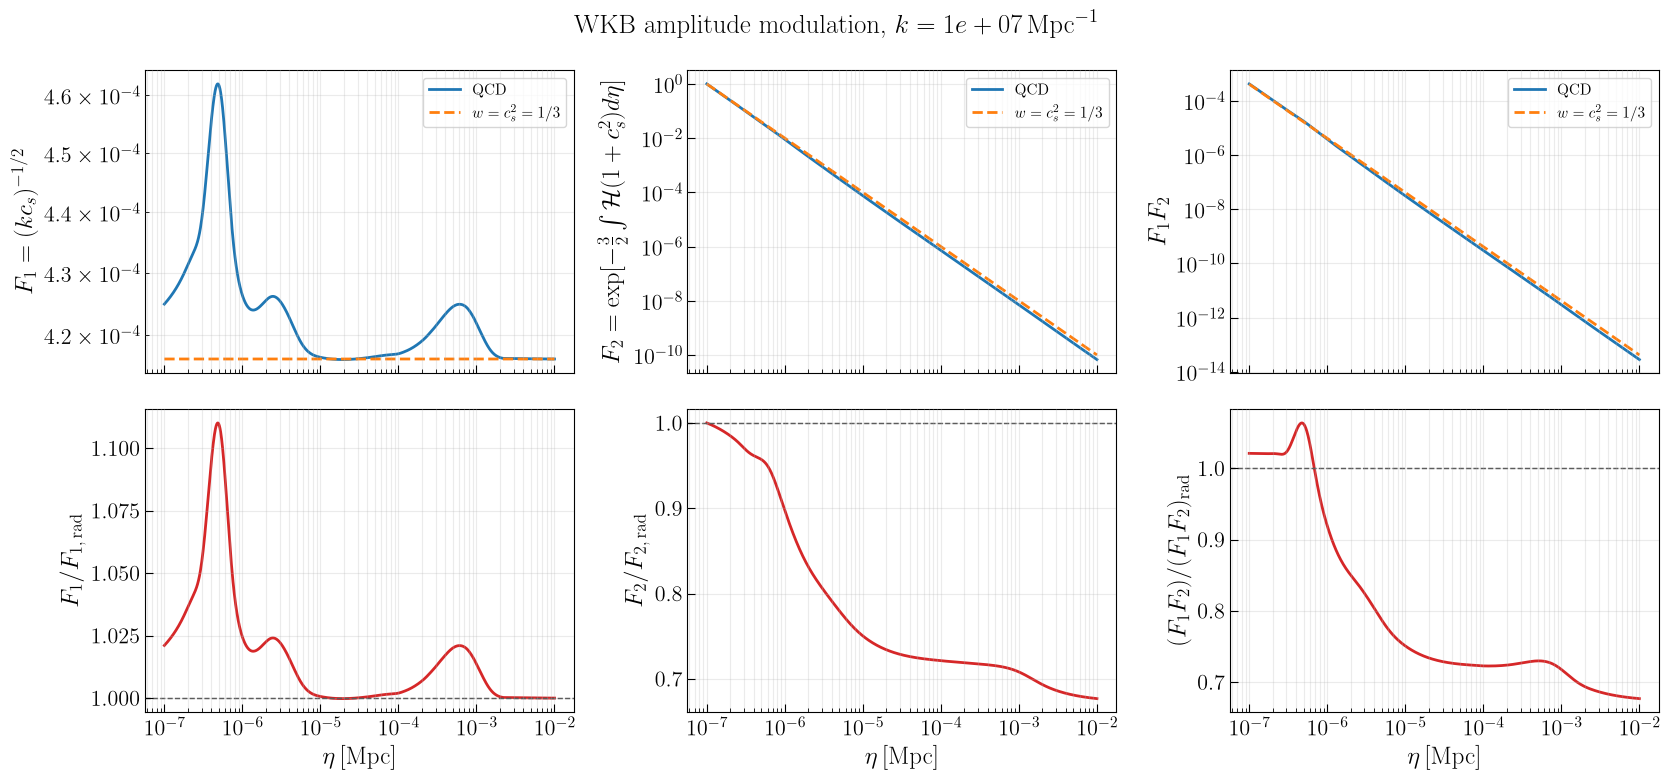

Max |F1/F1_rad - 1| = 1.101e-01
Max |F2/F2_rad - 1| = 3.232e-01
Max |Famp/Famp_rad - 1| = 3.232e-01


In [8]:
# WKB amplitude factors: compare the QCD background with w = c_s^2 = 1/3.
# The arbitrary overall normalization is removed by setting both F2 factors to
# unity at eta_wkb[0]; the ratios are therefore independent of this choice.
from scipy.integrate import cumulative_trapezoid

WKB_CHECK_K = 1.0e7       # Mpc^{-1}; only the absolute F1 normalization depends on k
# Start at horizon entry, eta >= 1/k, where the WKB form is applicable.
WKB_ETA_MIN = max(float(H_min_eta) * (1.0 + 1.0e-6), 1.0 / WKB_CHECK_K)
WKB_ETA_MAX = min(float(H_max_eta) * (1.0 - 1.0e-6), 1.0e-2)
if not WKB_ETA_MIN < WKB_ETA_MAX:
    raise ValueError(f'Invalid WKB eta interval: [{WKB_ETA_MIN:g}, {WKB_ETA_MAX:g}]')
eta_wkb = np.geomspace(WKB_ETA_MIN, WKB_ETA_MAX, 1200)

# First WKB factor: F1 = (k c_s)^(-1/2), with c_s = sqrt(c_s^2).
cs2_qcd = np.clip(np.asarray(c_s_sq(eta_wkb), dtype=float), 1.0e-15, None)
cs_qcd = np.sqrt(cs2_qcd)
cs_rad = np.sqrt(1.0 / 3.0)
F1_qcd = (WKB_CHECK_K * cs_qcd) ** (-0.5)
F1_rad = np.full_like(eta_wkb, (WKB_CHECK_K * cs_rad) ** (-0.5))

# Second WKB factor: F2 = exp[-3/2 integral H(1+c_s^2) d eta].
# For the radiation benchmark H = 1/eta, hence F2_rad = (eta/eta0)^(-2).
H_qcd = np.asarray(conH_interp(eta_wkb), dtype=float)
integrand_qcd = 1.5 * H_qcd * (1.0 + cs2_qcd)
log_F2_qcd = -np.concatenate(([0.0], cumulative_trapezoid(integrand_qcd, eta_wkb)))
F2_qcd = np.exp(log_F2_qcd)
F2_rad = (eta_wkb / eta_wkb[0]) ** (-2.0)

Famp_qcd = F1_qcd * F2_qcd
Famp_rad = F1_rad * F2_rad
ratio_F1 = F1_qcd / F1_rad
ratio_F2 = F2_qcd / F2_rad
ratio_Famp = Famp_qcd / Famp_rad

fig, axes = plt.subplots(2, 3, figsize=(17, 8), sharex='col')
absolute = ((F1_qcd, F1_rad, r'$F_1=(k c_s)^{-1/2}$'),
            (F2_qcd, F2_rad, r'$F_2=\exp[-\frac{3}{2}\int \mathcal{H}(1+c_s^2)d\eta]$'),
            (Famp_qcd, Famp_rad, r'$F_1F_2$'))
ratios = ((ratio_F1, r'$F_1/F_{1,\,\mathrm{rad}}$'),
          (ratio_F2, r'$F_2/F_{2,\,\mathrm{rad}}$'),
          (ratio_Famp, r'$(F_1F_2)/(F_1F_2)_{\mathrm{rad}}$'))
for ax, (qcd, rad, ylabel) in zip(axes[0], absolute):
    ax.loglog(eta_wkb, qcd, label='QCD')
    ax.loglog(eta_wkb, rad, '--', label=r'$w=c_s^2=1/3$')
    ax.set_ylabel(ylabel)
    ax.grid(True, which='both', alpha=0.25)
    ax.legend(fontsize=11)
for ax, (ratio, ylabel) in zip(axes[1], ratios):
    ax.semilogx(eta_wkb, ratio, color='C3')
    ax.axhline(1.0, color='0.25', ls='--', lw=1.0)
    ax.set_ylabel(ylabel)
    ax.grid(True, which='both', alpha=0.25)
for ax in axes[1]:
    ax.set_xlabel(r'$\eta\,[\mathrm{Mpc}]$')
fig.suptitle(fr'WKB amplitude modulation, $k={WKB_CHECK_K:.2g}\,\mathrm{{Mpc}}^{{-1}}$')
fig.tight_layout()
plt.show()

print(f'Max |F1/F1_rad - 1| = {np.max(np.abs(ratio_F1 - 1.0)):.3e}')
print(f'Max |F2/F2_rad - 1| = {np.max(np.abs(ratio_F2 - 1.0)):.3e}')
print(f'Max |Famp/Famp_rad - 1| = {np.max(np.abs(ratio_Famp - 1.0)):.3e}')


In [9]:
# Signed WKB phase shift across the QCD interval relative to c_s^2 = 1/3.
# Here "QCD interval" means cooling from 300 to 100 MeV; change these
# temperatures to test another explicit boundary convention.
QCD_T_START_MEV = 300.0
QCD_T_END_MEV = 100.0
PHASE_DELAY_K = WKB_CHECK_K  # Mpc^-1; phase shift scales linearly with k

def eta_at_temperature(temperature_mev, background_data):
    """Invert the monotone background T(eta) by interpolation in log space."""
    temperature_grid = np.asarray(background_data['temperature'], dtype=float)
    eta_grid = np.asarray(background_data['eta'], dtype=float)
    if not (temperature_grid[-1] <= temperature_mev <= temperature_grid[0]):
        raise ValueError('Requested temperature is outside the background grid.')
    return float(np.exp(np.interp(
        np.log(temperature_mev), np.log(temperature_grid[::-1]),
        np.log(eta_grid[::-1]),
    )))

def wkb_phase_delay_cycles(k, eta_start, eta_end, cs2_function, n_eta=10001):
    """Return (Delta theta, Delta theta/2pi) for c_s - 1/sqrt(3)."""
    if not (k > 0 and 0 < eta_start < eta_end and n_eta >= 3):
        raise ValueError('Require k > 0, 0 < eta_start < eta_end, n_eta >= 3.')
    eta_grid = np.geomspace(eta_start, eta_end, int(n_eta))
    cs2_grid = np.asarray(cs2_function(eta_grid), dtype=float)
    if np.any(~np.isfinite(cs2_grid)) or np.any(cs2_grid <= 0):
        raise ValueError('c_s^2 must be finite and positive on the integration grid.')
    delay_per_k = simpson(np.sqrt(cs2_grid) - 1.0 / np.sqrt(3.0), x=eta_grid)
    delta_theta = k * delay_per_k
    return delta_theta, delta_theta / (2.0 * np.pi)

eta_qcd_start = eta_at_temperature(QCD_T_START_MEV, background)
eta_qcd_end = eta_at_temperature(QCD_T_END_MEV, background)
phase_delay_rad, phase_delay_cycles = wkb_phase_delay_cycles(
    PHASE_DELAY_K, eta_qcd_start, eta_qcd_end, c_s_sq,
)
phase_delay_per_k_mpc = phase_delay_rad / PHASE_DELAY_K
print(f'QCD interval: T={QCD_T_START_MEV:g} -> {QCD_T_END_MEV:g} MeV')
print(f'eta interval: {eta_qcd_start:.6e} -> {eta_qcd_end:.6e} Mpc')
print(f'Integral of (c_s - 1/sqrt(3)) d eta = {phase_delay_per_k_mpc:.9e} Mpc')
print(f'k={PHASE_DELAY_K:.3e} Mpc^-1: Delta theta = {phase_delay_rad:.6f} rad '
      f'= {phase_delay_cycles:.6f} cycles')
print(f'At QCD start, k c_s / H = '
      f'{PHASE_DELAY_K * np.sqrt(c_s_sq(eta_qcd_start)) / conH_interp(eta_qcd_start):.3f}')


QCD interval: T=300 -> 100 MeV
eta interval: 2.260358e-07 -> 8.508873e-07 Mpc
Integral of (c_s - 1/sqrt(3)) d eta = -4.679765922e-08 Mpc
k=1.000e+07 Mpc^-1: Delta theta = -0.467977 rad = -0.074481 cycles
At QCD start, k c_s / H = 1.144


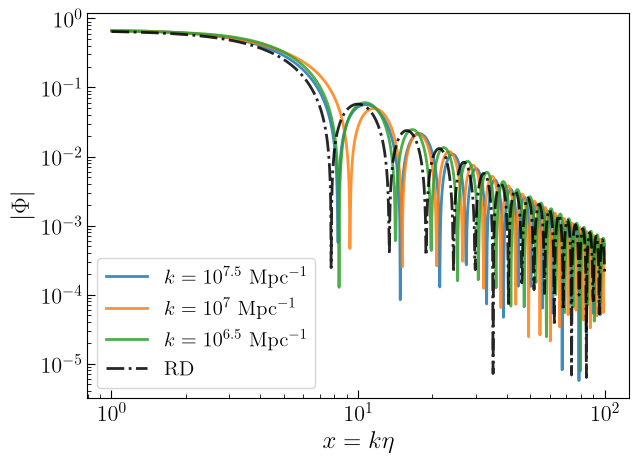

In [10]:
plt.figure(figsize=(7, 5))
k_value = 10**(7.5)
comparison_x = np.geomspace(1,1e+2,1000)
phi_radiation, _ = solve_phi_transfer(k_value, x_grid=comparison_x, initial_condition='analytic_superhorizon_v1')
plt.plot(comparison_x, abs(phi_radiation),  alpha=0.85, label=r'$k=10^{7.5}$ Mpc$^{{-1}}$')
k_value = 10**7
phi_radiation, _ = solve_phi_transfer(k_value, x_grid=comparison_x, initial_condition='analytic_superhorizon_v1')
plt.plot(comparison_x, abs(phi_radiation),  alpha=0.85, label=r'$k=10^{7}$ Mpc$^{{-1}}$')
k_value = 10**(6.5)
phi_radiation, _ = solve_phi_transfer(k_value, x_grid=comparison_x, initial_condition='analytic_superhorizon_v1')
plt.plot(comparison_x, abs(phi_radiation),  alpha=0.85, label=r'$k=10^{6.5}$ Mpc$^{{-1}}$')
plt.plot(comparison_x, abs(phi_ana(1e7,comparison_x/1e7)), color = 'black',alpha=0.85, ls='-.', label = 'RD')
plt.yscale('log')
plt.xscale('log')
plt.xlabel(r'$x=k\eta$')
plt.ylabel(r'$|\Phi|$')
plt.legend()
plt.show()

In [11]:
# Set this to True to regenerate missing/incompatible scalar transfer chunks.
# This can take a long time for the 1e6-1e8 chunk because it has many k modes.
if PHI_INITIAL_CONDITION not in {'analytic_superhorizon_v1', 'pure_radiation'}:
    raise ValueError(f'Unsupported PHI_INITIAL_CONDITION: {PHI_INITIAL_CONDITION!r}')
print(f'Phi cache initial condition: {PHI_INITIAL_CONDITION}')
RUN_PHI_PRECOMPUTE = True
if RUN_PHI_PRECOMPUTE:
    generate_missing_phi_chunks()
else:
    missing = [c.label for c in PHI_CHUNKS if not (_chunk_paths(c)['phi'].exists() and _chunk_paths(c)['phi_prime'].exists())]
    print('Phi precompute skipped. Missing updated-cache chunks:', missing)
    print('Existing original data/Phi_mat_1014.npy can still be read by the compatibility loader below.')


Phi cache initial condition: analytic_superhorizon_v1
Phi -20: 1/120
Phi -20: 6/120
Phi -20: 12/120
Phi -20: 18/120
Phi -20: 24/120
Phi -20: 30/120
Phi -20: 36/120
Phi -20: 42/120
Phi -20: 48/120
Phi -20: 54/120
Phi -20: 60/120
Phi -20: 66/120
Phi -20: 72/120
Phi -20: 78/120
Phi -20: 84/120
Phi -20: 90/120
Phi -20: 96/120
Phi -20: 102/120
Phi -20: 108/120
Phi -20: 114/120
Phi -20: 120/120
Phi 02: 1/120
Phi 02: 6/120
Phi 02: 12/120
Phi 02: 18/120
Phi 02: 24/120
Phi 02: 30/120
Phi 02: 36/120
Phi 02: 42/120
Phi 02: 48/120
Phi 02: 54/120
Phi 02: 60/120
Phi 02: 66/120
Phi 02: 72/120
Phi 02: 78/120
Phi 02: 84/120
Phi 02: 90/120
Phi 02: 96/120
Phi 02: 102/120
Phi 02: 108/120
Phi 02: 114/120
Phi 02: 120/120
Phi 24: 1/200
Phi 24: 10/200
Phi 24: 20/200
Phi 24: 30/200
Phi 24: 40/200
Phi 24: 50/200
Phi 24: 60/200
Phi 24: 70/200
Phi 24: 80/200
Phi 24: 90/200
Phi 24: 100/200
Phi 24: 110/200
Phi 24: 120/200
Phi 24: 130/200
Phi 24: 140/200
Phi 24: 150/200
Phi 24: 160/200
Phi 24: 170/200
Phi 24: 180/20

In [12]:
def _interp_rows_on_log_grid(values, x_grid, x_query):
    """Fast local cubic interpolation for one cached curve per query row."""
    values = np.asarray(values, dtype=float)
    x_grid = np.asarray(x_grid, dtype=float)
    x_query = np.asarray(x_query, dtype=float)
    if values.ndim != 2 or x_query.ndim != 2 or values.shape[0] != x_query.shape[0]:
        raise ValueError('values and x_query must be 2-D arrays with matching row counts.')

    rtol = 1e-10
    atol = 1e-14
    if np.any(x_query < x_grid[0] * (1.0 - rtol) - atol) or np.any(x_query > x_grid[-1] * (1.0 + rtol) + atol):
        raise ValueError(
            f'Prepared transfer requested outside x=[{x_grid[0]:.6g}, {x_grid[-1]:.6g}]'
        )
    x_clipped = np.clip(x_query, x_grid[0], x_grid[-1])
    log_x0 = math.log(x_grid[0])
    dlog_x = math.log(x_grid[-1] / x_grid[0]) / (len(x_grid) - 1)
    position = (np.log(x_clipped) - log_x0) / dlog_x
    i0 = np.clip(np.floor(position).astype(np.int64) - 1, 0, len(x_grid) - 4)
    z = position - i0

    # Four-point Lagrange interpolation on the uniform log(x) cache grid.
    out = np.take_along_axis(values, i0, axis=1)
    out *= -((z - 1.0) * (z - 2.0) * (z - 3.0)) / 6.0
    sample = np.take_along_axis(values, i0 + 1, axis=1)
    out += sample * (z * (z - 2.0) * (z - 3.0)) / 2.0
    sample = np.take_along_axis(values, i0 + 2, axis=1)
    out -= sample * (z * (z - 1.0) * (z - 3.0)) / 2.0
    sample = np.take_along_axis(values, i0 + 3, axis=1)
    out += sample * (z * (z - 1.0) * (z - 2.0)) / 6.0
    return out


def _interp_one_on_log_grid(values, x_grid, x_query):
    """Fast local cubic interpolation of one cached curve at an array of x."""
    query = np.asarray(x_query, dtype=float)
    flat = query.reshape(1, -1)
    repeated_values = np.asarray(values, dtype=float).reshape(1, -1)
    return _interp_rows_on_log_grid(repeated_values, x_grid, flat).reshape(query.shape)


class RowwiseCubicHermite:
    """Coupled value/derivative interpolation for one query grid per row."""
    def __init__(self, x_grid, values, derivatives):
        self.x_grid = np.asarray(x_grid, dtype=float)
        self.values = np.asarray(values, dtype=float)
        self.derivatives = np.asarray(derivatives, dtype=float)
        if self.values.shape != self.derivatives.shape or self.values.shape[1] != len(self.x_grid):
            raise ValueError('Hermite values and derivatives must match the x grid.')

    def _interval_data(self, x_query):
        x_query = np.asarray(x_query, dtype=float)
        if x_query.ndim != 2 or x_query.shape[0] != self.values.shape[0]:
            raise ValueError('Hermite transfer queries must be 2-D with one row per prepared mode.')
        rtol = 1e-10
        atol = 1e-14
        if (
            np.any(x_query < self.x_grid[0] * (1.0 - rtol) - atol)
            or np.any(x_query > self.x_grid[-1] * (1.0 + rtol) + atol)
        ):
            raise ValueError(
                f'Prepared transfer requested outside x=[{self.x_grid[0]:.6g}, {self.x_grid[-1]:.6g}]'
            )
        x_query = np.clip(x_query, self.x_grid[0], self.x_grid[-1])
        interval = np.searchsorted(self.x_grid, x_query, side='right') - 1
        interval = np.clip(interval, 0, len(self.x_grid) - 2)
        x0 = self.x_grid[interval]
        h = self.x_grid[interval + 1] - x0
        z = (x_query - x0) / h
        y0 = np.take_along_axis(self.values[:, :-1], interval, axis=1)
        y1 = np.take_along_axis(self.values[:, 1:], interval, axis=1)
        m0 = np.take_along_axis(self.derivatives[:, :-1], interval, axis=1)
        m1 = np.take_along_axis(self.derivatives[:, 1:], interval, axis=1)
        return z, h, y0, y1, m0, m1

    def value(self, x_query):
        z, h, y0, y1, m0, m1 = self._interval_data(x_query)
        z2 = z * z
        z3 = z2 * z
        return (
            (2.0 * z3 - 3.0 * z2 + 1.0) * y0
            + (z3 - 2.0 * z2 + z) * h * m0
            + (-2.0 * z3 + 3.0 * z2) * y1
            + (z3 - z2) * h * m1
        )

    def derivative(self, x_query):
        z, h, y0, y1, m0, m1 = self._interval_data(x_query)
        z2 = z * z
        return (
            (6.0 * z2 - 6.0 * z) * y0 / h
            + (3.0 * z2 - 4.0 * z + 1.0) * m0
            + (-6.0 * z2 + 6.0 * z) * y1 / h
            + (3.0 * z2 - 2.0 * z) * m1
        )


class PreparedRowwisePhi:
    def __init__(self, x_grid, phi, phi_prime_eta, mode_k):
        self.mode_k = np.asarray(mode_k, dtype=float)
        self.hermite = RowwiseCubicHermite(
            x_grid,
            phi,
            np.asarray(phi_prime_eta, dtype=float) / self.mode_k[:, None],
        )

    def phi(self, x_query):
        return self.hermite.value(x_query)

    def phi_prime(self, x_query):
        shape = (len(self.mode_k),) + (1,) * (np.ndim(x_query) - 1)
        return self.hermite.derivative(x_query) * self.mode_k.reshape(shape)


class PreparedPhiModes:
    def __init__(self, groups, shape):
        self.groups = groups
        self.shape = tuple(shape)

    def _eval(self, x, key):
        x = np.asarray(x, dtype=float)
        if x.shape[0] != self.shape[0]:
            raise ValueError('Prepared Phi rows no longer match the requested scalar modes.')
        out = np.empty_like(x, dtype=float)
        for group in self.groups:
            rows = group['rows']
            out[rows] = group[key](x[rows])
        return out

    def phi(self, x):
        return self._eval(x, 'phi')

    def phi_prime(self, x):
        return self._eval(x, 'phi_prime')


class PreparedPhiPair:
    def __init__(self, u_modes, v_modes):
        self.u_modes = u_modes
        self.v_modes = v_modes


class PiecewisePhiTransfer:
    def __init__(
        self,
        chunks=PHI_CHUNKS,
        prefer_updated=True,
        cache_dir=PHI_CACHE_DIR,
        allow_original=True,
    ):
        self.entries = []
        self.cache_dir = Path(cache_dir)
        for chunk in chunks:
            updated = _chunk_paths(chunk, directory=self.cache_dir)
            original_phi = DATA_DIR / f'Phi_mat_{chunk.label}.npy'
            original_prime = DATA_DIR / f'Phi_prime_mat_{chunk.label}.npy'
            if prefer_updated and updated['phi'].exists() and updated['phi_prime'].exists():
                phi_path = updated['phi']
                prime_path = updated['phi_prime']
                meta_path = updated['meta']
            elif allow_original and original_phi.exists() and original_prime.exists():
                phi_path = original_phi
                prime_path = original_prime
                meta_path = None
            else:
                continue

            phi = np.load(phi_path, mmap_mode='r')
            phi_prime = np.load(prime_path, mmap_mode='r')
            if phi.shape != phi_prime.shape:
                raise ValueError(f'Shape mismatch in Phi chunk {chunk.label}')
            if meta_path and meta_path.exists():
                meta = json.loads(meta_path.read_text())
                k_grid = np.geomspace(meta['k_min'], meta['k_max'], meta['n_k'])
                # Older Phi caches use a geometric x grid and omit x_grid metadata.
                x_grid = (phi_x_grid(meta['x_ini'], meta['x_final'], meta['n_x'])
                          if meta.get('x_grid') == 'log_linear'
                          else np.geomspace(meta['x_ini'], meta['x_final'], meta['n_x']))
            else:
                k_grid = np.geomspace(chunk.k_min, chunk.k_max, phi.shape[0])
                x_grid = np.geomspace(X_INI, X_FINAL, phi.shape[1])
            self.entries.append({
                'label': chunk.label,
                'k_min': float(k_grid[0]),
                'k_max': float(k_grid[-1]),
                'x_min': float(x_grid[0]),
                'x_max': float(x_grid[-1]),
                'x_grid': x_grid,
                'phi_interp': RectBivariateSpline(np.log10(k_grid), x_grid, phi, kx=3, ky=3, s=0),
                'prime_interp': RectBivariateSpline(np.log10(k_grid), x_grid, phi_prime, kx=3, ky=3, s=0),
            })
        if not self.entries:
            raise FileNotFoundError('No Phi chunks were found. Generate them first with RUN_PHI_PRECOMPUTE=True.')
        print('Loaded Phi chunks:', [e['label'] for e in self.entries])

    def _eval(self, k, x, key):
        k_arr, x_arr = np.broadcast_arrays(np.asarray(k, dtype=float), np.asarray(x, dtype=float))
        out = np.full(k_arr.shape, np.nan, dtype=float)
        k_flat = k_arr.ravel()
        x_flat = x_arr.ravel()
        out_flat = out.ravel()
        rtol = 1e-10
        atol = 1e-14
        for entry in self.entries:
            k_min, k_max = entry['k_min'], entry['k_max']
            x_min, x_max = entry['x_min'], entry['x_max']
            mask = (
                (k_flat >= k_min * (1.0 - rtol)) & (k_flat <= k_max * (1.0 + rtol)) &
                (x_flat >= x_min * (1.0 - rtol) - atol) & (x_flat <= x_max * (1.0 + rtol) + atol)
            )
            if np.any(mask):
                k_eval = np.clip(k_flat[mask], k_min, k_max)
                x_eval = np.clip(x_flat[mask], x_min, x_max)
                out_flat[mask] = entry[key].ev(np.log10(k_eval), x_eval)
        if np.any(~np.isfinite(out_flat)):
            bad = np.where(~np.isfinite(out_flat))[0][0]
            loaded = ', '.join(
                f"{e['label']}: k=[{e['k_min']:.3g}, {e['k_max']:.3g}], x=[{e['x_min']:.3g}, {e['x_max']:.3g}]"
                for e in self.entries
            )
            raise ValueError(
                f'Phi transfer requested outside cached range: k={k_flat[bad]:.12g}, x={x_flat[bad]:.12g}. '
                f'Loaded chunks: {loaded}. Generate a wider Phi chunk or reduce integration bounds.'
            )
        return float(out) if np.isscalar(k) and np.isscalar(x) else out

    def covers_k_range(self, k_min, k_max, rtol=1e-10):
        intervals = sorted((entry['k_min'], entry['k_max']) for entry in self.entries)
        target = float(k_min)
        end = float(k_max)
        for lo, hi in intervals:
            if hi < target * (1.0 - rtol):
                continue
            if lo > target * (1.0 + rtol):
                return False
            target = max(target, hi)
            if target >= end * (1.0 - rtol):
                return True
        return False

    def phi(self, k, x):
        return self._eval(k, x, 'phi_interp')

    def phi_prime(self, k, x):
        return self._eval(k, x, 'prime_interp')

    def prepare_modes(self, k_values):
        k_values = np.asarray(k_values, dtype=float).reshape(-1)
        entry_index = np.full(k_values.shape, -1, dtype=int)
        rtol = 1e-10
        for index, entry in enumerate(self.entries):
            mask = (
                (k_values >= entry['k_min'] * (1.0 - rtol))
                & (k_values <= entry['k_max'] * (1.0 + rtol))
            )
            entry_index[mask] = index
        if np.any(entry_index < 0):
            bad = int(np.where(entry_index < 0)[0][0])
            raise ValueError(f'Cannot prepare Phi transfer for k={k_values[bad]:.12g}.')

        groups = []
        for index in np.unique(entry_index):
            entry = self.entries[int(index)]
            rows = np.where(entry_index == index)[0]
            k_eval = np.clip(k_values[rows], entry['k_min'], entry['k_max'])
            unique_logk, inverse = np.unique(np.log10(k_eval), return_inverse=True)
            x_grid = entry['x_grid']
            phi_unique = entry['phi_interp'](unique_logk, x_grid, grid=True)
            prime_unique = entry['prime_interp'](unique_logk, x_grid, grid=True)
            transfer = PreparedRowwisePhi(
                x_grid,
                phi_unique[inverse],
                prime_unique[inverse],
                k_eval,
            )
            groups.append({
                'rows': rows,
                'x_grid': x_grid,
                'phi': transfer.phi,
                'phi_prime': transfer.phi_prime,
            })
        return PreparedPhiModes(groups, k_values.shape)

    def prepare_pair(self, u_values, v_values, tensor_k):
        return PreparedPhiPair(
            self.prepare_modes(np.asarray(u_values, dtype=float) * float(tensor_k)),
            self.prepare_modes(np.asarray(v_values, dtype=float) * float(tensor_k)),
        )


# Load explicitly after the needed Phi chunks exist. This avoids building large
# spline objects just by opening/running the notebook header.
LOAD_PHI_CACHE_NOW = True
phi_cache = PiecewisePhiTransfer() if LOAD_PHI_CACHE_NOW else None


Loaded Phi chunks: ['-20', '02', '24', '46', '68', '810', '1014', '1416']


## Tensor Green function

For the variable `g = a h`, the homogeneous equation is

\[
g_k'' + \left[k^2 - \frac{1-3w}{2}\mathcal{H}^2\right]g_k = 0.
\]

The derivative matrices below store `dg/deta`, so the Wronskian in the Green function has the correct conformal-time normalization.


In [13]:
GREEN_CHUNKS = [
    # Retain the established middle chunk and extend both ends at 100 points/dex.
    TransferChunk('13', 1e1, 1e3, 200),
    TransferChunk('310', 1e3, 1e10, 700),
    TransferChunk('1012', 1e10, 1e12, 200),
]
GREEN_RTOL = 3e-8
GREEN_ATOL = 1e-10
GREEN_X_FINAL = 1000.0  # Legacy cache endpoint; x>30 uses harmonic radiation extension.
GREEN_HARMONIC_FROM = 30.0


def green_rhs_x(x, y, k):
    g, dg_dx = y
    eta = x / k
    d2g_dx2 = -(1.0 - tensor_mass_over_k2(eta, k)) * g
    return [dg_dx, d2g_dx2]


def solve_green_modes(k, x_grid=None, rtol=GREEN_RTOL, atol=GREEN_ATOL):
    if x_grid is None:
        x_grid = np.geomspace(X_INI, GREEN_X_FINAL, N_X_DEFAULT)
    x0 = float(x_grid[0])
    # Two independent superhorizon-like basis functions. Only independence
    # matters for the Green function; the Wronskian handles normalization.
    y0_1 = [x0, 1.0]
    y0_2 = [1.0, 0.0]
    sol1 = solve_ivp(green_rhs_x, (x_grid[0], x_grid[-1]), y0_1, t_eval=x_grid, args=(float(k),), method='DOP853', rtol=rtol, atol=atol)
    sol2 = solve_ivp(green_rhs_x, (x_grid[0], x_grid[-1]), y0_2, t_eval=x_grid, args=(float(k),), method='DOP853', rtol=rtol, atol=atol)
    if not sol1.success:
        raise RuntimeError(f'Green mode 1 failed for k={k:.6g}: {sol1.message}')
    if not sol2.success:
        raise RuntimeError(f'Green mode 2 failed for k={k:.6g}: {sol2.message}')
    return sol1.y[0], float(k) * sol1.y[1], sol2.y[0], float(k) * sol2.y[1]


def _green_chunk_paths(chunk, directory=GREEN_CACHE_DIR):
    return {
        'g1': directory / f'g1_mat_{chunk.label}.npy',
        'g1_prime': directory / f'g1_prime_mat_{chunk.label}.npy',
        'g2': directory / f'g2_mat_{chunk.label}.npy',
        'g2_prime': directory / f'g2_prime_mat_{chunk.label}.npy',
        'meta': directory / f'green_meta_{chunk.label}.json',
    }


def save_green_chunk(chunk, n_x=N_X_DEFAULT, overwrite=False):
    paths = _green_chunk_paths(chunk)
    if not overwrite and all(paths[key].exists() for key in ('g1', 'g1_prime', 'g2', 'g2_prime')):
        # Reuse the established full-EoS Green cache.
        print(f'Green chunk {chunk.label} already exists; reusing it')
        return
    x_grid = np.geomspace(X_INI, GREEN_X_FINAL, int(n_x))
    k_grid = np.geomspace(chunk.k_min, chunk.k_max, chunk.n_k)
    mats = [np.empty((chunk.n_k, int(n_x)), dtype=np.float64) for _ in range(4)]
    for i, k in enumerate(k_grid, start=1):
        g1, g1p, g2, g2p = solve_green_modes(k, x_grid=x_grid)
        mats[0][i - 1] = g1
        mats[1][i - 1] = g1p
        mats[2][i - 1] = g2
        mats[3][i - 1] = g2p
        if i == 1 or i == chunk.n_k or i % max(1, chunk.n_k // 20) == 0:
            print(f'Green {chunk.label}: {i}/{chunk.n_k}')
    for key, mat in zip(('g1', 'g1_prime', 'g2', 'g2_prime'), mats):
        np.save(paths[key], mat)
    paths['meta'].write_text(json.dumps({
        'label': chunk.label,
        'k_min': chunk.k_min,
        'k_max': chunk.k_max,
        'n_k': chunk.n_k,
        'x_ini': X_INI,
        'x_final': GREEN_X_FINAL,
        'n_x': int(n_x),
        'prime': 'dg/deta',
        'tensor_include_w_correction': bool(TENSOR_INCLUDE_W_CORRECTION),
    }, indent=2))


def generate_missing_green_chunks(chunks=GREEN_CHUNKS, n_x=N_X_DEFAULT):
    for chunk in chunks:
        save_green_chunk(chunk, n_x=n_x, overwrite=False)


In [14]:
RUN_GREEN_PRECOMPUTE = True
if RUN_GREEN_PRECOMPUTE:
    generate_missing_green_chunks()
else:
    missing = [c.label for c in GREEN_CHUNKS if not all(_green_chunk_paths(c)[key].exists() for key in ('g1', 'g1_prime', 'g2', 'g2_prime'))]
    print('Green precompute skipped. Missing updated-cache chunks:', missing)


Green 13: 1/200
Green 13: 10/200
Green 13: 20/200
Green 13: 30/200
Green 13: 40/200
Green 13: 50/200
Green 13: 60/200
Green 13: 70/200
Green 13: 80/200
Green 13: 90/200
Green 13: 100/200
Green 13: 110/200
Green 13: 120/200
Green 13: 130/200
Green 13: 140/200
Green 13: 150/200
Green 13: 160/200
Green 13: 170/200
Green 13: 180/200
Green 13: 190/200
Green 13: 200/200
Green 310: 1/700
Green 310: 35/700
Green 310: 70/700
Green 310: 105/700
Green 310: 140/700
Green 310: 175/700
Green 310: 210/700
Green 310: 245/700
Green 310: 280/700
Green 310: 315/700
Green 310: 350/700
Green 310: 385/700
Green 310: 420/700
Green 310: 455/700
Green 310: 490/700
Green 310: 525/700
Green 310: 560/700
Green 310: 595/700
Green 310: 630/700
Green 310: 665/700
Green 310: 700/700
Green 1012: 1/200
Green 1012: 10/200
Green 1012: 20/200
Green 1012: 30/200
Green 1012: 40/200
Green 1012: 50/200
Green 1012: 60/200
Green 1012: 70/200
Green 1012: 80/200
Green 1012: 90/200
Green 1012: 100/200
Green 1012: 110/200
Green 101

In [15]:
class PreparedGreenAtK:
    """Green basis interpolated from the complete ODE solution cache.

    The cache is generated by ``solve_green_modes`` using the full background
    equation up to the cached range.  Beyond ``GREEN_HARMONIC_FROM`` the
    radiation-era homogeneous solution is continued analytically.
    """
    def __init__(self, k, entry):
        self.k = float(k)
        self.entry = entry
        self.x_grid = entry['x_grid']
        logk = math.log10(float(np.clip(k, entry['k_min'], entry['k_max'])))
        values = {
            key: entry[key](np.array([logk]), self.x_grid, grid=True)[0]
            for key in ('g1', 'g1p', 'g2', 'g2p')
        }
        self.mode1 = CubicHermiteSpline(
            self.x_grid, values['g1'], values['g1p'] / self.k,
            extrapolate=False,
        )
        self.mode2 = CubicHermiteSpline(
            self.x_grid, values['g2'], values['g2p'] / self.k,
            extrapolate=False,
        )
        self.mode1_at_switch = (float(self.mode1(GREEN_HARMONIC_FROM)), float(self.mode1(GREEN_HARMONIC_FROM, nu=1)))
        self.mode2_at_switch = (float(self.mode2(GREEN_HARMONIC_FROM)), float(self.mode2(GREEN_HARMONIC_FROM, nu=1)))
        self.basis = {
            'g1': lambda x: self._eval_mode(self.mode1, self.mode1_at_switch, x),
            'g1p': lambda x: self._eval_mode_prime(self.mode1, self.mode1_at_switch, x),
            'g2': lambda x: self._eval_mode(self.mode2, self.mode2_at_switch, x),
            'g2p': lambda x: self._eval_mode_prime(self.mode2, self.mode2_at_switch, x),
        }

    @staticmethod
    def _harmonic(value0, derivative0, delta):
        return value0 * np.cos(delta) + derivative0 * np.sin(delta)

    @staticmethod
    def _harmonic_prime(value0, derivative0, delta):
        return -value0 * np.sin(delta) + derivative0 * np.cos(delta)

    def _eval_mode(self, mode, anchor, x):
        scalar = np.ndim(x) == 0
        x = np.atleast_1d(np.asarray(x, dtype=float))
        out = np.empty_like(x, dtype=float)
        early = x <= GREEN_HARMONIC_FROM
        if np.any(early):
            out[early] = mode(x[early])
        if np.any(~early):
            out[~early] = self._harmonic(anchor[0], anchor[1], x[~early] - GREEN_HARMONIC_FROM)
        return float(out[0]) if scalar else out.reshape(np.asarray(x).shape)

    def _eval_mode_prime(self, mode, anchor, x):
        scalar = np.ndim(x) == 0
        x = np.atleast_1d(np.asarray(x, dtype=float))
        out = np.empty_like(x, dtype=float)
        early = x <= GREEN_HARMONIC_FROM
        if np.any(early):
            out[early] = self.k * mode(x[early], nu=1)
        if np.any(~early):
            out[~early] = self.k * self._harmonic_prime(anchor[0], anchor[1], x[~early] - GREEN_HARMONIC_FROM)
        return float(out[0]) if scalar else out.reshape(np.asarray(x).shape)

    def green(self, eta_bar, eta, k):
        if not np.isclose(float(k), self.k, rtol=1e-12, atol=0.0):
            raise ValueError(f'Prepared Green k={self.k:.12g} cannot evaluate k={float(k):.12g}.')
        x_bar = np.asarray(eta_bar, dtype=float) * self.k
        x = np.asarray(eta, dtype=float) * self.k
        x_all = np.concatenate([np.ravel(x_bar), np.ravel(x)])
        x_min_req = float(np.nanmin(x_all))
        if x_min_req < self.entry['x_min'] * (1.0 - 1e-10) - 1e-12:
            raise ValueError(
                f'Prepared Green requested outside cached x range '
                f'[{self.entry["x_min"]:.6g}, {self.entry["x_max"]:.6g}]'
            )
        x_bar = np.maximum(x_bar, self.entry['x_min'])
        x = np.maximum(np.broadcast_to(x, x_bar.shape), self.entry['x_min'])
        g1_bar = self.basis['g1'](x_bar)
        g1p_bar = self.basis['g1p'](x_bar)
        g2_bar = self.basis['g2'](x_bar)
        g2p_bar = self.basis['g2p'](x_bar)
        g1_eval = self.basis['g1'](x)
        g2_eval = self.basis['g2'](x)
        W = g1p_bar * g2_bar - g1_bar * g2p_bar
        return (g1_eval * g2_bar - g1_bar * g2_eval) / W


class PiecewiseGreen:
    def __init__(self, chunks=GREEN_CHUNKS, cache_dir=GREEN_CACHE_DIR):
        self.entries = []
        self.cache_dir = Path(cache_dir)
        for chunk in chunks:
            paths = _green_chunk_paths(chunk, directory=self.cache_dir)
            if not all(paths[key].exists() for key in ('g1', 'g1_prime', 'g2', 'g2_prime')):
                continue
            g1 = np.load(paths['g1'], mmap_mode='r')
            g1p = np.load(paths['g1_prime'], mmap_mode='r')
            g2 = np.load(paths['g2'], mmap_mode='r')
            g2p = np.load(paths['g2_prime'], mmap_mode='r')
            if paths['meta'].exists():
                meta = json.loads(paths['meta'].read_text())
                k_grid = np.geomspace(meta['k_min'], meta['k_max'], meta['n_k'])
                x_grid = np.geomspace(meta['x_ini'], meta['x_final'], meta['n_x'])
            else:
                k_grid = np.geomspace(chunk.k_min, chunk.k_max, g1.shape[0])
                x_grid = np.geomspace(X_INI, GREEN_X_FINAL, g1.shape[1])
            self.entries.append({
                'label': chunk.label,
                'k_min': float(k_grid[0]),
                'k_max': float(k_grid[-1]),
                'x_min': float(x_grid[0]),
                'x_max': float(x_grid[-1]),
                'x_grid': x_grid,
                'g1': RectBivariateSpline(np.log10(k_grid), x_grid, g1, kx=3, ky=3, s=0),
                'g1p': RectBivariateSpline(np.log10(k_grid), x_grid, g1p, kx=3, ky=3, s=0),
                'g2': RectBivariateSpline(np.log10(k_grid), x_grid, g2, kx=3, ky=3, s=0),
                'g2p': RectBivariateSpline(np.log10(k_grid), x_grid, g2p, kx=3, ky=3, s=0),
            })
        if not self.entries:
            raise FileNotFoundError('No Green chunks were found. Generate them first with RUN_GREEN_PRECOMPUTE=True.')
        print('Loaded Green chunks:', [e['label'] for e in self.entries])

    def _entry_for(self, k, x_values, rtol=1e-10, atol=1e-12):
        k = float(k)
        x_values = np.asarray(x_values, dtype=float)
        x_min_req = float(np.nanmin(x_values))
        x_max_req = float(np.nanmax(x_values))
        for entry in self.entries:
            k_min, k_max = entry['k_min'], entry['k_max']
            x_min, x_max = entry['x_min'], entry['x_max']
            k_ok = (k >= k_min * (1.0 - rtol)) and (k <= k_max * (1.0 + rtol))
            x_ok = (x_min_req >= x_min * (1.0 - rtol) - atol) and (x_max_req <= x_max * (1.0 + rtol) + atol)
            if k_ok and x_ok:
                return entry
        loaded = ', '.join(
            f"{e['label']}: k=[{e['k_min']:.3g}, {e['k_max']:.3g}], x=[{e['x_min']:.3g}, {e['x_max']:.3g}]"
            for e in self.entries
        )
        raise ValueError(
            f'Green function requested outside cached range for k={k:.12g}, x=[{x_min_req:.12g}, {x_max_req:.12g}]. '
            f'Loaded chunks: {loaded}. Generate a wider Green chunk or reduce integration bounds.'
        )

    def green(self, eta_bar, eta, k):
        return self.prepare_k(float(k)).green(eta_bar, eta, float(k))

    def prepare_k(self, k):
        # Only the exact-ODE segment needs cache coverage; later x is harmonic.
        entry = self._entry_for(float(k), [X_INI, GREEN_HARMONIC_FROM])
        return PreparedGreenAtK(float(k), entry)


def load_green_cache():
    return PiecewiseGreen()


## Source, time kernel, and kernel-grid cache

The source factor below is the `f` appearing in the Domenech review convention, but with the initial Newtonian-potential-to-curvature factor absorbed into `Phi`. Therefore the momentum integral should use `P_zeta`, not `P_Phi`.


In [16]:
def source_f_per_zeta(u, v, k, x_tensor, phi_transfer=None, prepared_phi=None):
    if phi_transfer is None and prepared_phi is None:
        raise ValueError('Pass phi_transfer=PiecewisePhiTransfer() after the Phi chunks have been generated/loaded.')
    eta = np.asarray(x_tensor, dtype=float) / float(k)
    H = conH_interp(eta)
    w = eos(eta)
    if prepared_phi is None:
        phi_u = phi_transfer.phi(u * k, u * x_tensor)
        phi_v = phi_transfer.phi(v * k, v * x_tensor)
        dphi_u = phi_transfer.phi_prime(u * k, u * x_tensor)
        dphi_v = phi_transfer.phi_prime(v * k, v * x_tensor)
    else:
        phi_u = prepared_phi.u_modes.phi(u * x_tensor)
        phi_v = prepared_phi.v_modes.phi(v * x_tensor)
        dphi_u = prepared_phi.u_modes.phi_prime(u * x_tensor)
        dphi_v = prepared_phi.v_modes.phi_prime(v * x_tensor)

    one_plus_w = 1.0 + w
    return (
        (5.0 + 3.0 * w) / (3.0 * one_plus_w) * phi_u * phi_v
        + 2.0 / (3.0 * one_plus_w) * (dphi_u * phi_v + dphi_v * phi_u) / H
        + 2.0 / (3.0 * one_plus_w) * dphi_u * dphi_v / H**2
    )


def choose_eta_min(u, v, k, x_min=X_INI, margin=1e-8):
    # Keep tensor and both scalar transfer-function arguments inside the cache.
    # The small margin avoids starting exactly on x_min, where roundoff can put
    # u*x or v*x a few ulps below the first cached grid point.
    smallest_multiplier = min(1.0, float(u), float(v))
    return x_min * (1.0 + margin) / (float(k) * smallest_multiplier)


def I_func_eta(u, v, k, eta, green_cache, phi_transfer=None, n_time=3000):
    eta_min = choose_eta_min(u, v, k)
    if eta <= eta_min:
        raise ValueError(f'eta={eta:.6g} is not larger than eta_min={eta_min:.6g}')
    eta_grid = np.geomspace(eta_min, eta, int(n_time))
    x_grid = float(k) * eta_grid
    integrand = (
        float(k)**2
        * a_interp(eta_grid) / a_interp(eta)
        * green_cache.green(eta_grid, eta, k)
        * source_f_per_zeta(u, v, k, x_grid, phi_transfer=phi_transfer)
    )
    return trapezoid(integrand, eta_grid)


def kernel_scaled_I2(u, v, k, green_cache, phi_transfer=None, x_eval=1e3, n_time=3000):
    # Returns (k / calH_c)^2 * average[I^2] at a time after source decay.
    # eta_c follows the original notebook's practical choice to keep scalar
    # arguments inside x <= x_eval for large u or v.
    max_mode = max(1.0, float(u), float(v))
    eta1 = float(x_eval) / (float(k) * max_mode)
    eta2 = eta1 - math.pi / (2.0 * float(k))
    if eta2 <= choose_eta_min(u, v, k):
        eta2 = eta1 + math.pi / (2.0 * float(k))
    I1 = I_func_eta(u, v, k, eta1, green_cache, phi_transfer=phi_transfer, n_time=n_time)
    I2 = I_func_eta(u, v, k, eta2, green_cache, phi_transfer=phi_transfer, n_time=n_time)
    avg_I2 = 0.5 * (I1**2 + I2**2)
    return avg_I2 * (float(k) / conH_interp(eta1))**2



def choose_eta_min_many(u, v, k, x_min=X_INI, margin=1e-8):
    u = np.asarray(u, dtype=float)
    v = np.asarray(v, dtype=float)
    smallest_multiplier = np.minimum(1.0, np.minimum(u, v))
    return x_min * (1.0 + margin) / (float(k) * smallest_multiplier)


def I_func_eta_many(
    u_values,
    v_values,
    k,
    eta_values,
    green_cache,
    phi_transfer=None,
    n_time=3000,
    prepared_phi=None,
):
    u_values = np.asarray(u_values, dtype=float)
    v_values = np.asarray(v_values, dtype=float)
    eta_values = np.asarray(eta_values, dtype=float)
    eta_min = choose_eta_min_many(u_values, v_values, k)
    if np.any(eta_values <= eta_min):
        bad = np.where(eta_values <= eta_min)[0][0]
        raise ValueError(f'eta={eta_values[bad]:.6g} is not larger than eta_min={eta_min[bad]:.6g}')

    frac = np.linspace(0.0, 1.0, int(n_time))
    log_eta_min = np.log(eta_min)[:, None]
    log_eta_max = np.log(eta_values)[:, None]
    eta_grid = np.exp(log_eta_min + (log_eta_max - log_eta_min) * frac[None, :])
    x_grid = float(k) * eta_grid
    u_col = u_values[:, None]
    v_col = v_values[:, None]

    integrand = (
        float(k)**2
        * a_interp(eta_grid) / a_interp(eta_values)[:, None]
        * green_cache.green(eta_grid, eta_values[:, None], k)
        * source_f_per_zeta(
            u_col,
            v_col,
            k,
            x_grid,
            phi_transfer=phi_transfer,
            prepared_phi=prepared_phi,
        )
    )
    return trapezoid(integrand, eta_grid, axis=1)


def kernel_scaled_I2_many(u_values, v_values, k, green_cache, phi_transfer=None, x_eval=1e3, n_time=3000):
    u_values = np.asarray(u_values, dtype=float)
    v_values = np.asarray(v_values, dtype=float)
    max_mode = np.maximum(1.0, np.maximum(u_values, v_values))
    eta1 = float(x_eval) / (float(k) * max_mode)
    eta2 = eta1 - math.pi / (2.0 * float(k))
    eta_min = choose_eta_min_many(u_values, v_values, k)
    eta2 = np.where(eta2 <= eta_min, eta1 + math.pi / (2.0 * float(k)), eta2)
    prepared_phi = (
        phi_transfer.prepare_pair(u_values, v_values, k)
        if hasattr(phi_transfer, 'prepare_pair')
        else None
    )
    prepared_green = green_cache.prepare_k(k) if hasattr(green_cache, 'prepare_k') else green_cache
    I1 = I_func_eta_many(
        u_values,
        v_values,
        k,
        eta1,
        prepared_green,
        phi_transfer=phi_transfer,
        n_time=n_time,
        prepared_phi=prepared_phi,
    )
    I2 = I_func_eta_many(
        u_values,
        v_values,
        k,
        eta2,
        prepared_green,
        phi_transfer=phi_transfer,
        n_time=n_time,
        prepared_phi=prepared_phi,
    )
    avg_I2 = 0.5 * (I1**2 + I2**2)
    return avg_I2 * (float(k) / conH_interp(eta1))**2


def _hybrid_source_eta_grid_many(eta_min, eta_end, k, n_time, x_switch=20.0):
    """Resolve both early logarithmic evolution and late oscillations."""
    eta_min = np.asarray(eta_min, dtype=float)
    eta_end = np.asarray(eta_end, dtype=float)
    n_time = int(n_time)
    if n_time < 512:
        raise ValueError('Hybrid source integration requires n_time >= 512.')

    x_min = float(k) * eta_min
    x_end = float(k) * eta_end
    n_log = min(max(256, n_time // 5), n_time - 2)
    n_linear = n_time - n_log + 1

    x_split = np.minimum(float(x_switch), 0.5 * x_end)
    x_split = np.maximum(x_split, x_min * (1.0 + 1e-10))
    x_split = np.minimum(x_split, x_end * (1.0 - 1e-10))

    early_fraction = np.linspace(0.0, 1.0, n_log)
    late_fraction = np.linspace(0.0, 1.0, n_linear)
    x_early = np.exp(
        np.log(x_min)[:, None]
        + (np.log(x_split) - np.log(x_min))[:, None] * early_fraction[None, :]
    )
    x_late = x_split[:, None] + (x_end - x_split)[:, None] * late_fraction[None, :]
    x_grid = np.concatenate([x_early[:, :-1], x_late], axis=1)
    return x_grid / float(k)


def kernel_scaled_I2_phase_average_many(
    u_values,
    v_values,
    k,
    green_cache,
    phi_transfer=None,
    x_source=1e3,
    n_time=6000,
    phase_periods=4,
    phase_samples=33,
):
    """Late-time kernel from frozen tensor-basis coefficients.

    The source is integrated once up to ``x_source`` for the fastest scalar
    mode. The resulting homogeneous tensor wave is then averaged over several
    I^2 periods, avoiding the phase bias of the original two-endpoint estimate.
    """
    u_values = np.asarray(u_values, dtype=float)
    v_values = np.asarray(v_values, dtype=float)
    if u_values.shape != v_values.shape or u_values.ndim != 1:
        raise ValueError('u_values and v_values must be one-dimensional arrays with matching shapes.')
    if phase_periods < 1 or phase_samples < 2 * int(phase_periods) + 1:
        raise ValueError('Use phase_periods >= 1 and at least two samples per I^2 period.')

    k = float(k)
    max_mode = np.maximum(1.0, np.maximum(u_values, v_values))
    eta_end = float(x_source) / (k * max_mode)
    eta_min = choose_eta_min_many(u_values, v_values, k)
    if np.any(eta_end <= eta_min):
        raise ValueError('x_source is too small for at least one scalar mode.')

    eta_grid = _hybrid_source_eta_grid_many(eta_min, eta_end, k, n_time)
    x_grid = k * eta_grid
    prepared_phi = (
        phi_transfer.prepare_pair(u_values, v_values, k)
        if hasattr(phi_transfer, 'prepare_pair')
        else None
    )
    prepared_green = green_cache.prepare_k(k) if hasattr(green_cache, 'prepare_k') else green_cache
    if not hasattr(prepared_green, 'basis'):
        raise TypeError('Phase averaging requires a prepared Green cache with homogeneous basis splines.')

    source = source_f_per_zeta(
        u_values[:, None],
        v_values[:, None],
        k,
        x_grid,
        phi_transfer=phi_transfer,
        prepared_phi=prepared_phi,
    )
    g1 = prepared_green.basis['g1'](x_grid)
    g1p = prepared_green.basis['g1p'](x_grid)
    g2 = prepared_green.basis['g2'](x_grid)
    g2p = prepared_green.basis['g2p'](x_grid)
    wronskian = g1p * g2 - g1 * g2p
    common = k**2 * a_interp(eta_grid) * source / wronskian
    coeff_g1 = simpson(common * g2, x=eta_grid, axis=1)
    coeff_g2 = simpson(common * g1, x=eta_grid, axis=1)

    phase_offset = np.linspace(0.0, float(phase_periods) * np.pi, int(phase_samples))
    x_phase = (k * eta_end)[:, None] + phase_offset[None, :]
    eta_phase = x_phase / k
    response = (
        prepared_green.basis['g1'](x_phase) * coeff_g1[:, None]
        - prepared_green.basis['g2'](x_phase) * coeff_g2[:, None]
    ) / a_interp(eta_phase)
    scaled_I2 = response**2 * (k / conH_interp(eta_phase))**2
    return trapezoid(scaled_I2, phase_offset, axis=1) / phase_offset[-1]


def st_to_uv(log10s, t):
    s = 10.0**np.asarray(log10s, dtype=float)
    t = np.asarray(t, dtype=float)
    u = 0.5 + s / np.sqrt(2.0) + t / np.sqrt(2.0)
    v = 0.5 + s / np.sqrt(2.0) - t / np.sqrt(2.0)
    return u, v


def projection_factor(u, v):
    u = np.asarray(u, dtype=float)
    v = np.asarray(v, dtype=float)
    return ((4.0 * v**2 - (1.0 - u**2 + v**2)**2) / (4.0 * u * v))**2


In [17]:
.5+1e-2/np.sqrt(2)


np.float64(0.5070710678118655)

In [18]:
kernel_scaled_I2(0.5070710678118655,0.5070710678118655,1e+7,load_green_cache(),PiecewisePhiTransfer())


Loaded Green chunks: ['13', '310', '1012']
Loaded Phi chunks: ['-20', '02', '24', '46', '68', '810', '1014', '1416']


np.float64(0.36260758511716323)

In [19]:
st_to_uv(-2,0)


(np.float64(0.5070710678118655), np.float64(0.5070710678118655))

In [20]:
def generate_kernel_grid(
    k_grid,
    log10s_grid=None,
    t_grid=None,
    green_cache=None,
    phi_transfer=None,
    n_time=3000,
    x_eval=1e3,
    output_path=None,
    t_batch_size=1,
    n_workers=1,
    kernel_evaluator=None,
):
    if log10s_grid is None:
        log10s_grid = default_kernel_log10s_grid()
    if t_grid is None:
        t_grid = default_kernel_t_grid()

    k_grid = np.asarray(k_grid, dtype=float)
    log10s_grid = np.asarray(log10s_grid, dtype=float)
    t_grid = np.asarray(t_grid, dtype=float)
    z = np.full((len(k_grid), len(t_grid), len(log10s_grid)), np.nan, dtype=np.float64)
    start_ik = 0
    partial_path = None
    if output_path is not None:
        output_path = Path(output_path)
        output_path.parent.mkdir(parents=True, exist_ok=True)
        partial_path = output_path.with_name(output_path.stem + '.partial.npz')
        if output_path.exists():
            cached = np.load(output_path)
            cached_n_time = int(cached['n_time']) if 'n_time' in cached.files else int(n_time)
            cached_x_eval = float(cached['x_eval']) if 'x_eval' in cached.files else float(x_eval)
            if (
                np.array_equal(cached['k_grid'], k_grid)
                and np.array_equal(cached['log10s_grid'], log10s_grid)
                and np.array_equal(cached['t_grid'], t_grid)
                and cached_n_time == int(n_time)
                and np.isclose(cached_x_eval, float(x_eval))
            ):
                print(f'Final kernel cache already exists: {output_path}', flush=True)
                return k_grid, log10s_grid, t_grid, cached['kernel']
        if partial_path.exists():
            partial = np.load(partial_path)
            partial_n_time = int(partial['n_time']) if 'n_time' in partial.files else int(n_time)
            partial_x_eval = float(partial['x_eval']) if 'x_eval' in partial.files else float(x_eval)
            if (
                np.array_equal(partial['k_grid'], k_grid)
                and np.array_equal(partial['log10s_grid'], log10s_grid)
                and np.array_equal(partial['t_grid'], t_grid)
                and partial_n_time == int(n_time)
                and np.isclose(partial_x_eval, float(x_eval))
            ):
                z[...] = partial['kernel']
                start_ik = int(partial.get('completed_k', 0))
                print(f'Resuming kernel grid from {partial_path} at k index {start_ik}/{len(k_grid)}', flush=True)

    # A matching final cache returns above without constructing several large
    # spline objects.  Transfer preflight is only needed when work remains.
    if start_ik < len(k_grid):
        scalar_k_min, scalar_k_max = ensure_phi_chunks_for_kernel(k_grid, log10s_grid, t_grid)
        if green_cache is None:
            green_cache = load_green_cache()
        if phi_transfer is None:
            phi_transfer = phi_cache if phi_cache is not None else PiecewisePhiTransfer()
        if not phi_transfer.covers_k_range(scalar_k_min, scalar_k_max):
            # A missing chunk may have just been generated by the preflight;
            # reload so the newly generated chunk is included.
            phi_transfer = PiecewisePhiTransfer()

    t_batch_size = max(1, int(t_batch_size))
    n_workers = max(1, int(n_workers))

    def compute_slice(ik):
        k = k_grid[ik]
        print(f'Kernel k {ik + 1}/{len(k_grid)}: log10(k)={np.log10(k):.3f}', flush=True)
        z_slice = np.empty((len(t_grid), len(log10s_grid)), dtype=np.float64)
        for it0 in range(0, len(t_grid), t_batch_size):
            it1 = min(it0 + t_batch_size, len(t_grid))
            s_mesh, t_mesh = np.meshgrid(log10s_grid, t_grid[it0:it1], indexing='xy')
            u_batch, v_batch = st_to_uv(s_mesh.ravel(), t_mesh.ravel())
            if kernel_evaluator is None:
                values = kernel_scaled_I2_many(
                    u_batch,
                    v_batch,
                    k,
                    green_cache,
                    phi_transfer=phi_transfer,
                    n_time=n_time,
                    x_eval=x_eval,
                )
            else:
                values = kernel_evaluator(
                    u_batch,
                    v_batch,
                    k,
                    green_cache,
                    phi_transfer,
                    n_time,
                    x_eval,
                )
            z_slice[it0:it1, :] = values.reshape(it1 - it0, len(log10s_grid))
            print(f'  k {ik + 1}: t rows {it0 + 1}-{it1}/{len(t_grid)} complete', flush=True)
        return ik, z_slice

    def save_checkpoint(completed_k):
        if partial_path is not None:
            np.savez_compressed(
                partial_path,
                k_grid=k_grid,
                log10s_grid=log10s_grid,
                t_grid=t_grid,
                kernel=z,
                completed_k=completed_k,
                x_eval=x_eval,
                n_time=n_time,
                tensor_include_w_correction=bool(TENSOR_INCLUDE_W_CORRECTION),
            )
            print(f'  checkpoint saved: {partial_path}', flush=True)

    if n_workers == 1:
        for ik in range(start_ik, len(k_grid)):
            completed_ik, z_slice = compute_slice(ik)
            z[completed_ik] = z_slice
            save_checkpoint(completed_ik + 1)
    else:
        print(f'Computing kernel slices with {n_workers} worker threads', flush=True)
        with ThreadPoolExecutor(max_workers=n_workers) as executor:
            for block_start in range(start_ik, len(k_grid), n_workers):
                block_stop = min(block_start + n_workers, len(k_grid))
                futures = [executor.submit(compute_slice, ik) for ik in range(block_start, block_stop)]
                for future in futures:
                    completed_ik, z_slice = future.result()
                    z[completed_ik] = z_slice
                save_checkpoint(block_stop)

    if output_path is not None:
        np.savez_compressed(output_path, k_grid=k_grid, log10s_grid=log10s_grid, t_grid=t_grid, kernel=z, x_eval=x_eval, n_time=n_time, tensor_include_w_correction=bool(TENSOR_INCLUDE_W_CORRECTION))
        print('Saved', output_path, flush=True)
    return k_grid, log10s_grid, t_grid, z


def load_kernel_interpolator(path):
    data = np.load(path)
    k_grid = data['k_grid']
    log10s_grid = data['log10s_grid']
    t_grid = data['t_grid']
    kernel = np.maximum(data['kernel'], np.finfo(float).tiny)
    interp = RegularGridInterpolator(
        (np.log10(k_grid), t_grid, log10s_grid),
        np.log10(kernel),
        bounds_error=False,
        fill_value=None,
    )

    def kernel_eval(k, log10s, t):
        k_arr, s_arr, t_arr = np.broadcast_arrays(np.asarray(k, dtype=float), np.asarray(log10s, dtype=float), np.asarray(t, dtype=float))
        points = np.column_stack([np.log10(k_arr.ravel()), t_arr.ravel(), s_arr.ravel()])
        vals = 10.0**interp(points)
        vals = vals.reshape(k_arr.shape)
        return float(vals) if np.isscalar(k) and np.isscalar(log10s) and np.isscalar(t) else vals

    # Keep the native grid available to momentum integrals.  Aligning the
    # quadrature with these cell boundaries removes the convergence noise that
    # appears when one global Gaussian rule crosses many interpolation kinks.
    kernel_eval.k_grid = k_grid
    kernel_eval.log10s_grid = log10s_grid
    kernel_eval.t_grid = t_grid
    kernel_eval.cache_path = Path(path)
    return kernel_eval


In [21]:
# Production configuration for the high-T calibrated background.
RUN_KERNEL_PRECOMPUTE = True
REFINED_CACHE_ROOT = CACHE_DIR
REFINED_PHI_CACHE_DIR = PHI_CACHE_DIR
REFINED_GREEN_CACHE_DIR = REFINED_CACHE_ROOT / 'green'
REFINED_KERNEL_CACHE_DIR = REFINED_CACHE_ROOT / 'kernel'
ORIGINAL_KERNEL_PATH = REFINED_KERNEL_CACHE_DIR / 'kernel_grid_fine_original_resolution.npz'


def refined_kernel_log10s_grid():
    resonance = np.log10((np.sqrt(3.0) - 1.0) / np.sqrt(2.0))
    broad = np.linspace(resonance - 0.075, resonance + 0.075, 61)
    offsets = np.geomspace(2e-5, 0.03, 60)
    near = np.r_[resonance - offsets[::-1], resonance, resonance + offsets]
    broad_fine = np.linspace(resonance - 0.10, resonance + 0.10, 101)
    offsets_fine = np.geomspace(5e-6, 0.04, 100)
    near_fine = np.r_[
        resonance - offsets_fine[::-1],
        resonance,
        resonance + offsets_fine,
    ]
    return np.unique(
        np.round(
            np.r_[
                default_kernel_log10s_grid(),
                broad,
                near,
                broad_fine,
                near_fine,
            ],
            12,
        )
    )


# Extend the endpoints only; retain the existing k spacing and refined band.
KERNEL_LOG10_K_MIN = 1.0
KERNEL_LOG10_K_MAX = 12.0
KERNEL_K_GRID = 10.0**np.unique(np.round(np.r_[
    np.arange(KERNEL_LOG10_K_MIN, 5.4, 0.05),
    np.arange(5.4, 7.0001, 0.02),
    np.arange(7.05, KERNEL_LOG10_K_MAX + 0.0001, 0.05),
], 10))
KERNEL_LOG10S_GRID = refined_kernel_log10s_grid()
KERNEL_N_S = len(KERNEL_LOG10S_GRID)
KERNEL_N_T = len(default_kernel_t_grid())
KERNEL_N_TIME = 4_000
KERNEL_N_WORKERS = 1
KERNEL_X_EVAL = 1_000.0
KERNEL_PHASE_PERIODS = 4
KERNEL_PHASE_SAMPLES = 33
KERNEL_BASE_PATH = REFINED_KERNEL_CACHE_DIR / 'kernel_grid_adaptive539_phaseavg_coupledinterp_x1000_t4000.npz'
KERNEL_PREVIOUS_PATH = REFINED_KERNEL_CACHE_DIR / 'kernel_grid_k1e3_1e9p9_adaptive539_phaseavg_coupledinterp_x1000_t4000.npz'
KERNEL_MISSING_K_PATH = REFINED_KERNEL_CACHE_DIR / 'kernel_grid_k1e1_1e12_missing_adaptive539_phaseavg_coupledinterp_x1000_t4000.npz'
KERNEL_PATH = REFINED_KERNEL_CACHE_DIR / 'kernel_grid_k1e1_1e12_adaptive539_phaseavg_coupledinterp_x1000_t4000.npz'

KERNEL_SCALAR_K_MIN, KERNEL_SCALAR_K_MAX = scalar_k_range_for_kernel(
    KERNEL_K_GRID, KERNEL_LOG10S_GRID, default_kernel_t_grid()
)
PHI_K_MIN = min(chunk.k_min for chunk in PHI_CHUNKS)
PHI_K_MAX = max(chunk.k_max for chunk in PHI_CHUNKS)
GREEN_K_MIN = min(chunk.k_min for chunk in GREEN_CHUNKS)
GREEN_K_MAX = max(chunk.k_max for chunk in GREEN_CHUNKS)
if KERNEL_SCALAR_K_MIN < PHI_K_MIN or KERNEL_SCALAR_K_MAX > PHI_K_MAX:
    raise ValueError(
        f'Phi cache range [{PHI_K_MIN:g}, {PHI_K_MAX:g}] does not cover '
        f'the kernel scalar-mode range [{KERNEL_SCALAR_K_MIN:g}, {KERNEL_SCALAR_K_MAX:g}].'
    )
if KERNEL_K_GRID[0] < GREEN_K_MIN or KERNEL_K_GRID[-1] > GREEN_K_MAX:
    raise ValueError(
        f'Green cache range [{GREEN_K_MIN:g}, {GREEN_K_MAX:g}] does not cover '
        f'the tensor-kernel range [{KERNEL_K_GRID[0]:g}, {KERNEL_K_GRID[-1]:g}].'
    )
print(
    f'Kernel tensor k range: [{KERNEL_K_GRID[0]:.6g}, {KERNEL_K_GRID[-1]:.6g}] '
    f'({len(KERNEL_K_GRID)} points); required scalar k range: '
    f'[{KERNEL_SCALAR_K_MIN:.6g}, {KERNEL_SCALAR_K_MAX:.6g}]'
)


def production_kernel_evaluator(u, v, k, green_cache, phi_transfer, n_time, x_eval):
    return kernel_scaled_I2_phase_average_many(
        u,
        v,
        k,
        green_cache,
        phi_transfer=phi_transfer,
        x_source=x_eval,
        n_time=n_time,
        phase_periods=KERNEL_PHASE_PERIODS,
        phase_samples=KERNEL_PHASE_SAMPLES,
    )


def extend_kernel_cache_from_base(
    base_path=KERNEL_BASE_PATH, missing_k_path=KERNEL_MISSING_K_PATH,
    output_path=KERNEL_PATH, previous_path=KERNEL_PREVIOUS_PATH,
):
    """Reuse validated slices and compute missing k values at either end, with resume."""
    base_path = Path(base_path)
    missing_k_path = Path(missing_k_path)
    output_path = Path(output_path)
    previous_path = Path(previous_path) if previous_path is not None else None
    target_k = np.asarray(KERNEL_K_GRID, dtype=float)
    target_s = KERNEL_LOG10S_GRID
    target_t = default_kernel_t_grid()

    def read_cache(path, expected_k=None):
        with np.load(path) as data:
            k = np.asarray(data['k_grid'], dtype=float)
            values = np.asarray(data['kernel'], dtype=float)
            indices = np.searchsorted(target_k, k)
            in_grid = (
                k.ndim == 1 and len(k) > 0 and np.all(np.diff(k) > 0)
                and np.all(indices < len(target_k))
                and np.array_equal(target_k[indices], k)
            )
            checks = {
                'k grid': in_grid and (expected_k is None or np.array_equal(k, expected_k)),
                'log10s grid': np.array_equal(data['log10s_grid'], target_s),
                't grid': np.array_equal(data['t_grid'], target_t),
                'kernel shape': values.shape == (len(k), len(target_t), len(target_s)),
                'finite kernel': np.all(np.isfinite(values)),
                'n_time': int(data['n_time']) == KERNEL_N_TIME,
                'x_eval': np.isclose(float(data['x_eval']), KERNEL_X_EVAL),
            }
            # Legacy full-EoS phase-average caches did not store these fields.
            # Their established settings were w correction on, 4 periods, 33 samples.
            for key, expected, legacy in (
                ('tensor_include_w_correction', bool(TENSOR_INCLUDE_W_CORRECTION), True),
                ('phase_periods', KERNEL_PHASE_PERIODS, 4),
                ('phase_samples', KERNEL_PHASE_SAMPLES, 33),
            ):
                checks[key] = (data[key].item() if key in data.files else legacy) == expected
            failed = [name for name, passed in checks.items() if not passed]
            if failed:
                raise ValueError(f'Kernel cache {path} is incompatible: ' + ', '.join(failed))
        return k, indices, values

    if output_path.exists():
        read_cache(output_path, expected_k=target_k)
        print('Kernel cache already exists; reusing', output_path)
        return

    # Prefer the previous merged grid. If neither legacy cache exists, build
    # the target grid using the same production evaluator and checkpoint code.
    reuse_path = previous_path if previous_path is not None and previous_path.exists() else base_path
    merged_kernel = np.empty((len(target_k), len(target_t), len(target_s)))
    missing_mask = np.ones(len(target_k), dtype=bool)
    reused_count = 0
    if reuse_path.exists():
        base_k, base_indices, base_kernel = read_cache(reuse_path)
        merged_kernel[base_indices] = base_kernel
        missing_mask[base_indices] = False
        reused_count = len(base_k)
    missing_k = target_k[missing_mask]

    if len(missing_k):
        # generate_kernel_grid validates k/s/t grids and time settings before
        # reusing its completed or partial cache, and checkpoints each k slice.
        refined_phi = PiecewisePhiTransfer(
            cache_dir=REFINED_PHI_CACHE_DIR, allow_original=False
        )
        refined_green = PiecewiseGreen(cache_dir=REFINED_GREEN_CACHE_DIR)
        generate_kernel_grid(
            missing_k,
            log10s_grid=target_s,
            t_grid=target_t,
            green_cache=refined_green,
            phi_transfer=refined_phi,
            n_time=KERNEL_N_TIME,
            x_eval=KERNEL_X_EVAL,
            output_path=missing_k_path,
            n_workers=KERNEL_N_WORKERS,
            kernel_evaluator=production_kernel_evaluator,
        )
        _, _, missing_kernel = read_cache(missing_k_path, expected_k=missing_k)
        merged_kernel[missing_mask] = missing_kernel

    output_path.parent.mkdir(parents=True, exist_ok=True)
    building_path = output_path.with_name(output_path.stem + '.building.npz')
    np.savez_compressed(
        building_path,
        k_grid=target_k,
        log10s_grid=target_s,
        t_grid=target_t,
        kernel=merged_kernel,
        x_eval=KERNEL_X_EVAL,
        n_time=KERNEL_N_TIME,
        tensor_include_w_correction=bool(TENSOR_INCLUDE_W_CORRECTION),
        phase_periods=KERNEL_PHASE_PERIODS,
        phase_samples=KERNEL_PHASE_SAMPLES,
        base_cache=str(reuse_path) if reused_count else '',
        missing_k_cache=str(missing_k_path) if len(missing_k) else '',
    )
    building_path.replace(output_path)
    print(
        f'Saved merged kernel cache {output_path}: {len(missing_k)} computed + '
        f'{reused_count} reused = {len(target_k)} slices'
    )


if RUN_KERNEL_PRECOMPUTE:
    extend_kernel_cache_from_base()
else:
    print('Kernel precompute skipped. Expected cache path:', KERNEL_PATH)


Kernel tensor k range: [10, 1e+12] (269 points); required scalar k range: [0.120963, 7.17057e+13]
Loaded Phi chunks: ['-20', '02', '24', '46', '68', '810', '1014', '1416']
Loaded Green chunks: ['13', '310', '1012']
Kernel scalar transfer k range: [0.120963, 7.17057e+13]
Kernel k 1/269: log10(k)=1.000
  k 1: t rows 1-1/20 complete
  k 1: t rows 2-2/20 complete
  k 1: t rows 3-3/20 complete
  k 1: t rows 4-4/20 complete
  k 1: t rows 5-5/20 complete
  k 1: t rows 6-6/20 complete
  k 1: t rows 7-7/20 complete
  k 1: t rows 8-8/20 complete
  k 1: t rows 9-9/20 complete
  k 1: t rows 10-10/20 complete
  k 1: t rows 11-11/20 complete
  k 1: t rows 12-12/20 complete
  k 1: t rows 13-13/20 complete
  k 1: t rows 14-14/20 complete
  k 1: t rows 15-15/20 complete
  k 1: t rows 16-16/20 complete
  k 1: t rows 17-17/20 complete
  k 1: t rows 18-18/20 complete
  k 1: t rows 19-19/20 complete
  k 1: t rows 20-20/20 complete
  checkpoint saved: C:\Research\92_real_IGW_at_PTA\sigw\SIGW_EOS\SIGW_EOS\da

# GW compute
## Momentum integral and present-day spectrum

The Gaussian scalar result is evaluated in the Domenech convention,

\[
\Omega_{\rm GW}(k,\eta_c)=\frac{2}{3}\int du\,dv\,\mathcal{P}(u,v)
\left(\frac{k}{\mathcal{H}_c}\right)^2\overline{I^2}\,P_\zeta(ku)P_\zeta(kv).
\]

The code multiplies by the redshift factor from arXiv:2307.01653 to return `Omega_GW h^2` today. If you want the generation-time fraction instead, set `include_today_factor=False`.


In [22]:
def _gauss_legendre_interval(a, b, n):
    nodes, weights = leggauss(int(n))
    x = 0.5 * (b - a) * nodes + 0.5 * (a + b)
    w = 0.5 * (b - a) * weights
    return x, w


def _composite_gauss_legendre(grid, lower, upper, order):
    grid = np.asarray(grid, dtype=float)
    if lower < grid[0] or upper > grid[-1] or upper <= lower:
        raise ValueError(
            f'Integration interval [{lower:g}, {upper:g}] is outside '
            f'the kernel grid [{grid[0]:g}, {grid[-1]:g}].'
        )
    edges = np.concatenate(([lower], grid[(grid > lower) & (grid < upper)], [upper]))
    nodes, weights = leggauss(int(order))
    lo = edges[:-1, None]
    hi = edges[1:, None]
    x = 0.5 * (hi - lo) * nodes + 0.5 * (hi + lo)
    w = 0.5 * (hi - lo) * weights
    return x.ravel(), w.ravel()


def omega_gw_h2(
    k_values,
    P_zeta,
    kernel_eval,
    log10s_bounds=(-2.0, 2.0),
    n_s=160,
    n_t=80,
    include_today_factor=True,
    eta_f=None,
    x_eval=1e3,
    quadrature='auto',
    cell_order=4,
):
    k_values = np.atleast_1d(np.asarray(k_values, dtype=float))
    native_s = getattr(kernel_eval, 'log10s_grid', None)
    native_t = getattr(kernel_eval, 't_grid', None)
    use_composite = quadrature == 'kernel_grid' or (
        quadrature == 'auto' and native_s is not None and native_t is not None
    )
    if quadrature not in {'auto', 'kernel_grid', 'global'}:
        raise ValueError("quadrature must be 'auto', 'kernel_grid', or 'global'.")
    if quadrature == 'kernel_grid' and (native_s is None or native_t is None):
        raise ValueError('kernel_grid quadrature requires a kernel loaded by load_kernel_interpolator().')

    if use_composite:
        s_nodes, s_weights = _composite_gauss_legendre(
            native_s, log10s_bounds[0], log10s_bounds[1], cell_order
        )
        t_nodes, t_weights = _composite_gauss_legendre(
            native_t, 0.0, native_t[-1], cell_order
        )
    else:
        s_nodes, s_weights = _gauss_legendre_interval(log10s_bounds[0], log10s_bounds[1], n_s)
        t_nodes, t_weights = _gauss_legendre_interval(0.0, default_kernel_t_grid()[-1], n_t)
    S, T = np.meshgrid(s_nodes, t_nodes, indexing='xy')
    WS, WT = np.meshgrid(s_weights, t_weights, indexing='xy')
    U, V = st_to_uv(S, T)
    jac = 10.0**S * np.log(10.0)
    sym = 2.0  # integrate t >= 0 and use u-v symmetry
    geom = projection_factor(U, V)
    weight_2d = WS * WT

    out = []
    for k in k_values:
        K = kernel_eval(k, S, T)
        integrand = sym * (2.0 / 3.0) * jac * geom * K * P_zeta(U * k) * P_zeta(V * k)
        if include_today_factor:
            eta_c = x_eval / (k * np.maximum.reduce([np.ones_like(U), U, V]))
            integrand = integrand * today_redshift_factor(eta_c, eta_f=eta_f)
        out.append(np.sum(weight_2d * integrand))
    out = np.array(out)
    return float(out[0]) if np.ndim(k_values) == 1 and len(k_values) == 1 else out


def P_log_normal(k, kp, width=0.01, amplitude=1.0):
    k = np.asarray(k, dtype=float)
    return amplitude * np.exp(-0.5 * (np.log(k / kp) / width)**2) / (np.sqrt(2.0 * np.pi) * width)


def P_flat(k, A_zeta=1.0):
    """Scale-invariant curvature spectrum, P_zeta(k)=A_zeta."""
    k = np.asarray(k, dtype=float)
    return np.full_like(k, float(A_zeta), dtype=float)


def omega_gw_delta_peak(
    k_values,
    kp,
    kernel_eval,
    amplitude=1.0,
    log10s_bounds=(-2.0, 2.0),
    t_max=0.7,
    include_today_factor=False,
    eta_f=None,
    x_eval=1e3,
):
    """Spectrum for P_zeta=A*delta(ln(k/kp)), reduced analytically."""
    scalar_input = np.ndim(k_values) == 0
    k_values = np.atleast_1d(np.asarray(k_values, dtype=float))
    if np.any(k_values <= 0.0) or kp <= 0.0:
        raise ValueError('k_values and kp must be positive.')

    r = k_values / float(kp)
    s = np.sqrt(2.0) * (1.0 / r - 0.5)
    s_min, s_max = 10.0**log10s_bounds[0], 10.0**log10s_bounds[1]
    out = np.zeros_like(r)
    valid = (r < 2.0) & (s >= s_min) & (s <= s_max) & (t_max >= 0.0)
    if np.any(valid):
        u = 1.0 / r[valid]
        geom = projection_factor(u, u)
        kernel = kernel_eval(
            k_values[valid],
            np.log10(s[valid]),
            np.zeros(np.count_nonzero(valid)),
        )
        values = (2.0 / 3.0) * amplitude**2 * u**2 * geom * kernel
        if include_today_factor:
            eta_c = x_eval / (k_values[valid] * np.maximum(1.0, u))
            values *= today_redshift_factor(eta_c, eta_f=eta_f)
        out[valid] = values
    return float(out[0]) if scalar_input else out


def omega_gw_lognormal_narrow(
    k_values,
    kp,
    kernel_eval,
    width=0.01,
    amplitude=1.0,
    n_gauss=120,
    sigma_cut=7.0,
    log10s_bounds=(-2.0, 2.0),
    t_max=0.7,
    include_today_factor=False,
    eta_f=None,
    x_eval=1e3,
    return_retained_weight=False,
):
    """Resolve a narrow log-normal spectrum in Gaussian peak coordinates.

    This avoids asking a broad fixed (log10(s), t) quadrature to find the
    Delta-wide peak.  The transformed variables are the independent Gaussian
    combinations of ln(u*k/kp) and ln(v*k/kp).
    """
    scalar_input = np.ndim(k_values) == 0
    k_values = np.atleast_1d(np.asarray(k_values, dtype=float))
    if np.any(k_values <= 0.0) or kp <= 0.0:
        raise ValueError('k_values and kp must be positive.')
    if width <= 0.0 or sigma_cut <= 0.0 or int(n_gauss) < 4:
        raise ValueError('width and sigma_cut must be positive, with n_gauss >= 4.')

    p, wp = _gauss_legendre_interval(-sigma_cut, sigma_cut, n_gauss)
    q, wq = _gauss_legendre_interval(0.0, sigma_cut, n_gauss)
    P, Q = np.meshgrid(p, q, indexing='xy')
    WP, WQ = np.meshgrid(wp, wq, indexing='xy')
    gaussian_weight = (WP * WQ / np.pi) * np.exp(-0.5 * (P**2 + Q**2))
    alpha = width * (P + Q) / np.sqrt(2.0)
    beta = width * (P - Q) / np.sqrt(2.0)
    exp_alpha = np.exp(alpha)
    exp_beta = np.exp(beta)
    s_min, s_max = 10.0**log10s_bounds[0], 10.0**log10s_bounds[1]

    out = np.zeros_like(k_values)
    retained = np.zeros_like(k_values)
    for index, k in enumerate(k_values):
        r = float(k / kp)
        u = exp_alpha / r
        v = exp_beta / r
        s = (u + v - 1.0) / np.sqrt(2.0)
        t = (u - v) / np.sqrt(2.0)
        valid = (s >= s_min) & (s <= s_max) & (t >= 0.0) & (t <= t_max)
        retained[index] = np.sum(gaussian_weight[valid])
        if not np.any(valid):
            continue
        geom = projection_factor(u[valid], v[valid])
        kernel = kernel_eval(
            np.full(np.count_nonzero(valid), k),
            np.log10(s[valid]),
            t[valid],
        )
        values = (2.0 / 3.0) * amplitude**2 * u[valid] * v[valid] * geom * kernel
        if include_today_factor:
            eta_c = x_eval / (k * np.maximum.reduce([np.ones(np.count_nonzero(valid)), u[valid], v[valid]]))
            values *= today_redshift_factor(eta_c, eta_f=eta_f)
        out[index] = np.sum(gaussian_weight[valid] * values)

    if scalar_input:
        spectrum_result = float(out[0])
        retained_result = float(retained[0])
    else:
        spectrum_result = out
        retained_result = retained
    return (spectrum_result, retained_result) if return_retained_weight else spectrum_result


def P_power_law_compact(k, A_zeta=1.0, k_star=2e7, n_s=1.0, k_min=1e5, k_max=1e8):
    k = np.asarray(k, dtype=float)
    out = A_zeta * (k / k_star)**(n_s - 1.0)
    out = np.where((k >= k_min) & (k <= k_max), out, 0.0)
    return out


In [23]:
x=np.atleast_1d(np.asarray((1e4, 1e6), dtype=float))


In [24]:
# 先确认缓存文件确实存在
print(KERNEL_PATH, KERNEL_PATH.exists())

# 从 .npz cache 创建 (k, log10s, t) -> kernel 的插值函数
if not KERNEL_PATH.exists():
    raise FileNotFoundError(
        f'{KERNEL_PATH} is absent for the new high-T background. '
        'Generate Phi, Green, and kernel caches for this background before computing spectra.'
    )
kernel_eval = load_kernel_interpolator(KERNEL_PATH)


C:\Research\92_real_IGW_at_PTA\sigw\SIGW_EOS\SIGW_EOS\data\QCD_adiabatic_highT\kernel\kernel_grid_k1e1_1e12_adaptive539_phaseavg_coupledinterp_x1000_t4000.npz True


In [25]:

k_eval = np.geomspace(1e1, 10**12, 300)
omega_flat_today = omega_gw_h2(
    k_eval,
    lambda k: P_flat(k, 1.0),
    kernel_eval,
    x_eval=KERNEL_X_EVAL,
    include_today_factor = True
)


In [26]:
import csv
with open(DATA_DIR / f'flat_QCD_new.csv', 'w', newline='', encoding='utf-8') as csvfile:
    csv_writer = csv.writer(csvfile)
    
    csv_writer.writerow(['k', 'OmegaGW'])
    
    for row in zip(k_eval,omega_flat_today):
        csv_writer.writerow(row)


In [27]:
import csv
with open(DATA_DIR / f'flat_QCD_entropy.csv', 'w', newline='', encoding='utf-8') as csvfile:
    csv_writer = csv.writer(csvfile)
    
    csv_writer.writerow(['k', 'entropy'])
    
    for row in zip(k_eval,    today_redshift_factor(1 / k_eval, 1e-4)/ today_redshift_factor(1e-1, 1e-4)):
        csv_writer.writerow(row)


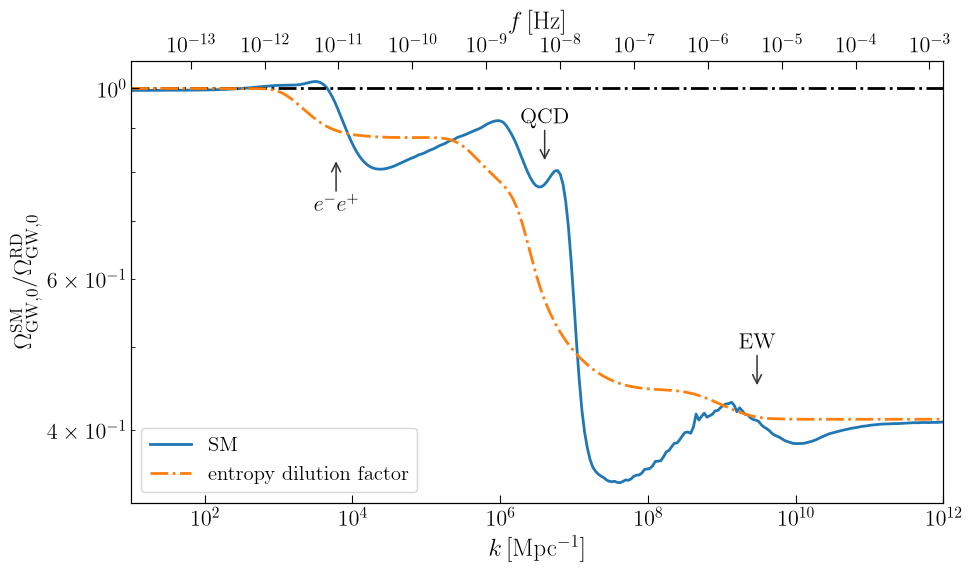

In [58]:
fig, ax = plt.subplots(figsize=(10, 6))
standard_flat = 3.45334986e-05
data = np.loadtxt(DATA_DIR / f'flat_QCD_new.csv', delimiter=",", skiprows=1)
kspan = data[:, 0]
OmegaGW = data[:, 1]
ax.plot(kspan, OmegaGW / standard_flat, label='SM')

data = np.loadtxt('data/flat_QCD.csv', delimiter=",", skiprows=1)
kspan = data[:, 0]
OmegaGW = data[:, 1]
#ax.plot(kspan, OmegaGW / standard_flat, label='old')

ax.set_xscale('log')
ax.set_xlabel(r'$k\,[\rm Mpc^{-1}]$')
ax.set_ylabel(r'$\Omega_{\mathrm{GW,0}}^{\mathrm{SM}}/\Omega_{\mathrm{GW,0}}^{\mathrm{RD}}$')
ax.axhline(1, ls='-.', color='black')
ax.set_xlim(1e1, 1e12)
ax.loglog(
    kspan,
    today_redshift_factor(1 / kspan, 1e-4)
    / today_redshift_factor(1e-1, 1e-4),
    ls='-.',
    label=r'entropy dilution factor',
)

# Upper horizontal axis: cyclic frequency today, f = k c / (2 pi).
# Use decade ticks and display them as 10^n.
ax_frequency = ax.twiny()
ax_frequency.set_xscale('log')
ax_frequency.set_xlim(ax.get_xlim())
f_min = k_mpc_to_hz(ax.get_xlim()[0])
f_max = k_mpc_to_hz(ax.get_xlim()[1])
f_exponents = np.arange(
    int(np.ceil(np.log10(f_min))),
    int(np.floor(np.log10(f_max))) + 1,
)
f_ticks = 10.0**f_exponents
k_ticks = hz_to_k_mpc(f_ticks)
ax_frequency.set_xticks(k_ticks)
ax_frequency.set_xticklabels([
    rf'$10^{{{exponent:d}}}$' for exponent in f_exponents
])
ax_frequency.set_xlabel(r'$f\,[\rm Hz]$')

# Independent label positions.  Change these y values manually as needed.
electron_text_y = 0.7
qcd_text_y = 0.85
ew_text_y = 0.34
transition_x = {
    'e-e+': 6e3,
    'QCD': 4e6,
    'EW': 3e9,
}
arrow_length = 0.08
arrow_style = dict(
    arrowstyle='->', color='0.2', lw=1.1,
    shrinkA=0, shrinkB=2,
)

# The arrow is defined relative to each text position, so moving a label
# moves its arrow together with it.  e-e+ points upward; QCD and EW downward.
ax.annotate(
    r'$e^-e^+$',
    xy=(transition_x['e-e+'], electron_text_y + arrow_length),
    xycoords=('data', 'axes fraction'),
    xytext=(transition_x['e-e+'], electron_text_y),
    textcoords=('data', 'axes fraction'),
    ha='center', va='top', arrowprops=arrow_style,
)
for label, x_target, text_y in (
    ('QCD', transition_x['QCD'], qcd_text_y),
    ('EW', transition_x['EW'], ew_text_y),
):
    ax.annotate(
        label,
        xy=(x_target, text_y - arrow_length),
        xycoords=('data', 'axes fraction'),
        xytext=(x_target, text_y),
        textcoords=('data', 'axes fraction'),
        ha='center', va='bottom', arrowprops=arrow_style,
    )

ax.legend()
fig.tight_layout()
plt.savefig('plot/flat_GWspectrum_QCD2.pdf')
plt.show()


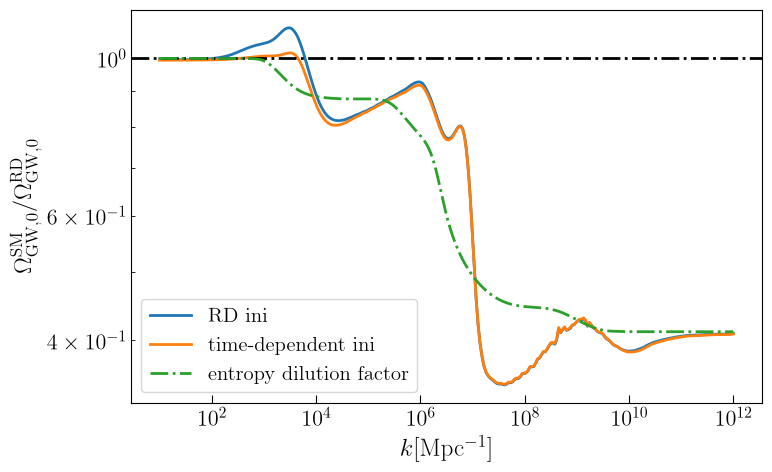

In [56]:
standard_flat = 3.4555910205756e-05
plt.figure(figsize=(8, 5))
data = np.loadtxt('data/flat_QCD_ini_new.csv', delimiter=",", skiprows=1)
kspan = data[:,0]
OmegaGW2 =data[:,1]
plt.loglog(kspan,OmegaGW2/standard_flat,label='RD ini')
data = np.loadtxt('data/flat_QCD_new.csv', delimiter=",", skiprows=1)
kspan = data[:,0]
OmegaGW =data[:,1]
plt.loglog(kspan,OmegaGW/standard_flat,label='time-dependent ini')
plt.axhline(1, ls='-.', color='black')
plt.xlabel(r'$k [\rm Mpc^{-1}]$')
plt.ylabel(r'$\Omega_{\rm GW,0}^{\rm SM}/\Omega_{\rm GW,0}^{\rm RD}$')
plt.loglog(kspan, today_redshift_factor(1/kspan,1e-4)/today_redshift_factor(1e-2,1e-4),ls='-.',label=r'entropy dilution factor')
plt.legend()
plt.tight_layout()
plt.savefig('plot/QCDspectrum_initial condition.pdf')
plt.show()


## QCD delta-spectrum scan and interpolation

The following cells generate the QCD-aware induced-GW spectrum for a delta-like primordial curvature spectrum over a grid of peak scales, then build a reusable interpolator in `(log k_peak, log x)` with `x=k/k_peak`. The scan is cached one CSV file per peak scale and is disabled by default.


In [30]:
# QCD delta-spectrum scan and interpolation
# The scan refreshes the delta CSV cache using the current grid.
DELTA_QCD_DIR = DATA_DIR / 'gw_delta'
DELTA_QCD_DIR.mkdir(parents=True, exist_ok=True)
DELTA_QCD_X_MIN = 1e-2
DELTA_QCD_X_MAX = 2.0
DELTA_QCD_N_X = 5000
DELTA_QCD_LOG10_KP_MIN = 4.0
DELTA_QCD_LOG10_KP_MAX = 9.9
DELTA_QCD_LOG10_KP_STEP = 0.01
DELTA_QCD_SCAN_VERSION = 'qcd-delta-v1'
RUN_DELTA_QCD_SCAN = False


# 先确认缓存文件确实存在
print(KERNEL_PATH, KERNEL_PATH.exists())

# 从 .npz cache 创建 (k, log10s, t) -> kernel 的插值函数
if not KERNEL_PATH.exists():
    raise FileNotFoundError(
        f'{KERNEL_PATH} is absent for the new high-T background. '
        'Generate Phi, Green, and kernel caches for this background before computing spectra.'
    )
kernel_eval = load_kernel_interpolator(KERNEL_PATH)


def _delta_qcd_scan_grid(
    log10_kp_min=DELTA_QCD_LOG10_KP_MIN,
    log10_kp_max=DELTA_QCD_LOG10_KP_MAX,
    log10_kp_step=DELTA_QCD_LOG10_KP_STEP,
    x_min=DELTA_QCD_X_MIN,
    x_max=DELTA_QCD_X_MAX,
    n_x=DELTA_QCD_N_X,
):
    if not (0 < x_min < x_max and int(n_x) >= 2):
        raise ValueError('Require 0 < x_min < x_max and n_x >= 2.')
    exponents = np.arange(
        float(log10_kp_min),
        float(log10_kp_max) + 0.5 * float(log10_kp_step),
        float(log10_kp_step),
    )
    k_peak_grid = 10.0**np.round(exponents, 10)
    x_grid = np.geomspace(float(x_min), float(x_max), int(n_x))
    return k_peak_grid, x_grid


def _delta_qcd_scan_metadata(
    k_peak_grid, x_grid, include_today_factor, x_eval,
):
    return {
        'version': DELTA_QCD_SCAN_VERSION,
        'x_min': float(x_grid[0]),
        'x_max': float(x_grid[-1]),
        'n_x': int(len(x_grid)),
        'k_peak_min': float(k_peak_grid[0]),
        'k_peak_max': float(k_peak_grid[-1]),
        'n_k_peak': int(len(k_peak_grid)),
        'include_today_factor': bool(include_today_factor),
        'x_eval': float(x_eval),
    }


def generate_delta_qcd_scan(
    kernel=kernel_eval,
    output_dir=DELTA_QCD_DIR,
    log10_kp_min=DELTA_QCD_LOG10_KP_MIN,
    log10_kp_max=DELTA_QCD_LOG10_KP_MAX,
    log10_kp_step=DELTA_QCD_LOG10_KP_STEP,
    x_min=DELTA_QCD_X_MIN,
    x_max=DELTA_QCD_X_MAX,
    n_x=DELTA_QCD_N_X,
    include_today_factor=True,
    x_eval=KERNEL_X_EVAL,
    skip=False,
    force=True,
):
    """Generate cached QCD delta spectra, one CSV per k_peak."""
    output_dir = Path(output_dir)
    output_dir.mkdir(parents=True, exist_ok=True)
    k_peak_grid, x_grid = _delta_qcd_scan_grid(
        log10_kp_min, log10_kp_max, log10_kp_step,
        x_min, x_max, n_x,
    )
    metadata = _delta_qcd_scan_metadata(
        k_peak_grid, x_grid, include_today_factor, x_eval,
    )
    metadata_path = output_dir / '_scan_metadata.json'
    # A forced scan is a complete cache refresh. Remove stale tables first,
    # including files from an older x or k_peak range, so the interpolator
    # cannot accidentally mix incompatible grids.
    if force:
        for stale_file in output_dir.glob('delta_kp_*.csv'):
            stale_file.unlink()
    metadata_path.write_text(json.dumps(metadata, indent=2), encoding='utf-8')

    generated = []
    for index, k_peak in enumerate(k_peak_grid, start=1):
        filename = output_dir / f'delta_kp_{np.log10(k_peak):.2f}.csv'
        reuse = False
        if skip and filename.exists() and not force:
            try:
                table = np.loadtxt(filename, delimiter=',', skiprows=1)
                reuse = (
                    table.shape == (len(x_grid), 2)
                    and np.allclose(table[:, 0] / k_peak, x_grid, rtol=2e-10, atol=0.0)
                    and np.all(np.isfinite(table[:, 1]))
                )
            except (OSError, ValueError):
                reuse = False
        if reuse:
            continue

        k_values = k_peak * x_grid
        omega = omega_gw_delta_peak(
            k_values,
            k_peak,
            kernel,
            include_today_factor=include_today_factor,
            x_eval=x_eval,
        )
        np.savetxt(
            filename,
            np.column_stack((k_values, omega)),
            delimiter=',',
            header='k,OmegaGW_h2',
            comments='',
        )
        generated.append(filename)
        print(f'Delta QCD {index}/{len(k_peak_grid)}: saved {filename}')

    metadata_path.write_text(json.dumps(metadata, indent=2), encoding='utf-8')
    return {
        'files': generated,
        'k_peak_grid': k_peak_grid,
        'x_grid': x_grid,
        'metadata': metadata,
    }


if RUN_DELTA_QCD_SCAN:
    delta_qcd_scan = generate_delta_qcd_scan()
else:
    print('QCD delta scan skipped. Set RUN_DELTA_QCD_SCAN=True to generate/reuse the CSV cache.')


C:\Research\92_real_IGW_at_PTA\sigw\SIGW_EOS\SIGW_EOS\data\QCD_adiabatic_highT\kernel\kernel_grid_k1e1_1e12_adaptive539_phaseavg_coupledinterp_x1000_t4000.npz True
QCD delta scan skipped. Set RUN_DELTA_QCD_SCAN=True to generate/reuse the CSV cache.


In [31]:
from scipy.interpolate import RegularGridInterpolator


def load_delta_qcd_interpolator(delta_dir=DELTA_QCD_DIR):
    """Load QCD delta tables and interpolate log(Omega) on (log k_peak, log x)."""
    delta_dir = Path(delta_dir)
    files = sorted(delta_dir.glob('delta_kp_*.csv'))
    if not files:
        raise FileNotFoundError(f'No delta_kp_*.csv files found in {delta_dir}.')

    first = np.loadtxt(files[0], delimiter=',', skiprows=1)
    if first.ndim != 2 or first.shape[1] != 2:
        raise ValueError(f'Unexpected table shape in {files[0]}: {first.shape}.')
    if np.any(first[:, 0] <= 0) or not np.all(np.diff(first[:, 0]) > 0):
        raise ValueError(f'Physical-k column must be strictly increasing in {files[0]}.')

    x_grid = DELTA_QCD_X_MIN * first[:, 0] / first[0, 0]
    rows = []
    for filename in files:
        table = np.loadtxt(filename, delimiter=',', skiprows=1)
        if table.shape != first.shape:
            raise ValueError(
                f'Unexpected table shape in {filename}: {table.shape}; expected {first.shape}.'
            )
        if np.any(table[:, 0] <= 0) or not np.all(np.diff(table[:, 0]) > 0):
            raise ValueError(f'Physical-k column must be strictly increasing in {filename}.')
        reconstructed_x = DELTA_QCD_X_MIN * table[:, 0] / table[0, 0]
        if not np.allclose(reconstructed_x, x_grid, rtol=2e-10, atol=0.0):
            raise ValueError(f'Inconsistent normalized-k grid in {filename}.')
        k_peak = float(table[0, 0] / x_grid[0])
        rows.append((k_peak, table[:, 1]))

    rows.sort(key=lambda row: row[0])
    k_peak_grid = np.array([row[0] for row in rows])
    omega_grid = np.stack([row[1] for row in rows])
    interpolator = RegularGridInterpolator(
        (np.log(k_peak_grid), np.log(x_grid)),
        np.log(np.maximum(omega_grid, np.finfo(float).tiny)),
        method='linear',
        bounds_error=True,
    )

    def delta_qcd_spectrum(k_peak, x):
        scalar_input = np.ndim(k_peak) == 0 and np.ndim(x) == 0
        kp_arr, x_arr = np.broadcast_arrays(
            np.asarray(k_peak, dtype=float), np.asarray(x, dtype=float)
        )
        if np.any(kp_arr <= 0.0) or np.any(x_arr <= 0.0):
            raise ValueError('k_peak and x must be positive.')
        points = np.column_stack((np.log(kp_arr.ravel()), np.log(x_arr.ravel())))
        values = np.exp(interpolator(points)).reshape(kp_arr.shape)
        return float(values.flat[0]) if scalar_input else values

    delta_qcd_spectrum.k_peak_grid = k_peak_grid
    delta_qcd_spectrum.x_grid = x_grid
    delta_qcd_spectrum.interpolator = interpolator
    delta_qcd_spectrum.data_dir = delta_dir
    return delta_qcd_spectrum


DELTA_QCD_K_PEAK_GRID, delta_qcd_log_interpolator = (
    None, None
)
if any(DELTA_QCD_DIR.glob('delta_kp_*.csv')):
    delta_qcd_spectrum = load_delta_qcd_interpolator()
    DELTA_QCD_K_PEAK_GRID = delta_qcd_spectrum.k_peak_grid
    delta_qcd_log_interpolator = delta_qcd_spectrum.interpolator
    print(
        f'Loaded {len(DELTA_QCD_K_PEAK_GRID)} QCD delta tables; '
        f'x range = [{delta_qcd_spectrum.x_grid[0]:g}, {delta_qcd_spectrum.x_grid[-1]:g}]'
    )
else:
    delta_qcd_spectrum = None
    print('QCD delta interpolator not built: no CSV cache found yet.')


Loaded 591 QCD delta tables; x range = [0.01, 2]


In [32]:
# Compatibility interface: S(x, f_peak)
# Keep the plotting API used in SIGW_EoS.ipynb.  Here f_peak is in Hz,
# x=k/k_peak; the returned spectrum already is Omega_GW,0 h^2.
F_PEAK_TO_K_MPC = 6.468e14
DELTA_X_MATCH = 0.05  # analytic IR continuation begins at x=f/f_peak=0.05


def S(x, f_peak, return_diagnostics=False):
    """Return the QCD delta spectrum using the legacy ``S(x, f_peak)`` API.

    Parameters
    ----------
    x : array_like
        Dimensionless frequency ratio k/k_peak.
    f_peak : float
        Peak frequency in Hz.  It is converted to k_peak in Mpc^-1 using
        the project convention ``k_peak = f_peak * 6.468e14``.
    return_diagnostics : bool, optional
        Return the spectrum and a small metadata dictionary when true.

    The cached QCD tables cover ``DELTA_QCD_X_MIN <= x <=
    DELTA_QCD_X_MAX``. Below x_match=0.05 (inside the momentum window) the standard
    delta-spectrum ``x^2 log^2(x)`` infrared continuation is used; above
    the upper endpoint the finite-support spectrum is set to zero.
    """
    if delta_qcd_spectrum is None:
        raise RuntimeError(
            'QCD delta tables are not loaded. Run generate_delta_qcd_scan() '
            'first, then rerun the interpolator cell.'
        )
    if f_peak <= 0.0:
        raise ValueError('f_peak must be positive.')

    scalar_input = np.ndim(x) == 0
    x_array = np.atleast_1d(np.asarray(x, dtype=float))
    if np.any(x_array <= 0.0):
        raise ValueError('x must be positive.')

    k_peak = float(f_peak) * F_PEAK_TO_K_MPC
    kp_grid = delta_qcd_spectrum.k_peak_grid
    if not (kp_grid[0] <= k_peak <= kp_grid[-1]):
        raise ValueError(
            f'k_peak={k_peak:.6g} is outside the QCD delta-table range '
            f'[{kp_grid[0]:.6g}, {kp_grid[-1]:.6g}].'
        )

    x_min = float(delta_qcd_spectrum.x_grid[0])
    x_match = max(DELTA_X_MATCH, x_min)
    x_max = float(delta_qcd_spectrum.x_grid[-1])
    output = np.zeros_like(x_array)

    numerical = (x_array >= x_match) & (x_array <= x_max)
    if np.any(numerical):
        output[numerical] = delta_qcd_spectrum(k_peak, x_array[numerical])

    infrared = x_array < x_match
    if np.any(infrared):
        omega_min = float(delta_qcd_spectrum(k_peak, x_match))
        x_ir = x_array[infrared]
        output[infrared] = omega_min * (x_ir / x_match)**2
        output[infrared] *= (np.log(x_ir) / np.log(x_match))**2

    diagnostics = {
        'k_peak': k_peak,
        'f_peak': float(f_peak),
        'x_min': x_min,
        'x_match': x_match,
        'x_max': x_max,
        'infrared_continuation': bool(np.any(infrared)),
        'outside_uv_support': bool(np.any(x_array > x_max)),
    }
    spectrum = float(output[0]) if scalar_input else output
    return (spectrum, diagnostics) if return_diagnostics else spectrum


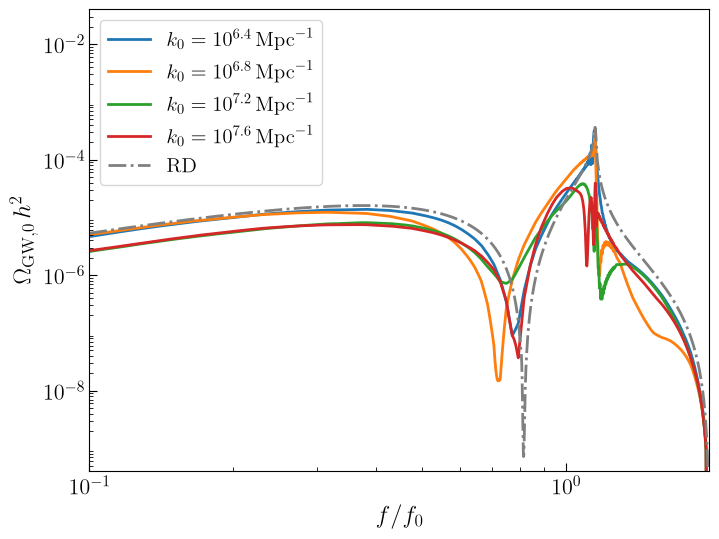

In [33]:
import matplotlib.ticker as mticker
# Inspect the raw cached scan over its full x range, without IR matching.
kspan = np.geomspace(1e-2, 2.0, 10**4)
fig, ax = plt.subplots(1, 1, figsize=(8, 6))
kp = np.geomspace(10**(6.4),10**(7.6),4)
for kps in kp:
    OmegaGW = delta_qcd_spectrum(kps, kspan)
    plt.plot(kspan,OmegaGW,label = rf'$k_0=10^{{{np.log10(kps):.1f}}}\,\mathrm{{Mpc}}^{{-1}}$')

data = np.loadtxt('data/GW_ad_delta.csv', delimiter=",", skiprows=1)
kspan = data[:,0]
OmegaGW =data[:,1]
plt.plot(kspan,OMEGA_R0_H2*OmegaGW,color='gray',ls = '-.',label='RD')

plt.xscale('log')
plt.yscale('log')
plt.xlabel(r'$f/f_0$')
plt.ylabel(r'$\Omega_{\mathrm{GW},0}\,h^2$')
plt.legend()
ax.set_xlim(1e-1, 2.0)
plt.ylim(4e-10,4e-2)
ax.set_xticks([0.1, 1])
ax.xaxis.set_minor_formatter(mticker.NullFormatter())
plt.yticks([1e-8,1e-6,1e-4,1e-2])
plt.savefig('../../../output/delta_pure.pdf')
plt.show()


## QCD BPL-spectrum scan and interpolation

Use the same scan / loader / interface / plot structure as the delta subsection, with
\[
\mathcal P_\zeta(q)=A\min[(q/k_0)^3,1],\qquad x=k/k_0.
\]
The convolution uses the existing QCD kernel and `omega_gw_h2`, including its
present-day redshift factor (the CSV values already are $\Omega_{\mathrm{GW},0}h^2$).
The BPL scan uses the full $-2\leq\log_{10}s\leq2$ window without a
second convergence-check integral. For newly generated rows the legacy
relative-change column is -1 (not evaluated); old rows retain their values.
The scan plots cover $10^{-2}\leq x\leq10^2$ for BPL and
$10^{-2}\leq x\leq2$ for delta, including less-converged points.
Below the first trusted point of each turnover table, match the finite-width BPL
IR asymptote $x^3\ln^2(1/x)$ and continue down to $x=10^{-2}$ before
interpolating across turnover scales. This is an approximate IR continuation
normalized to the QCD result, without an additional frequency-dependent QCD
propagation correction. Diagnostics distinguish it from trusted direct points.
There is no UV continuation; the delta $x^2$ tail does not apply to BPL.

The scan is disabled by default. Tables in `data/GW_BPL_QCD/` have columns
`k,OmegaGW_h2,relative_change_vs_smax_31p6,computed_cached_window`, with $k$ in
$\mathrm{Mpc}^{-1}$ and $A=1$ by default. `_scan_metadata.json` records the grid,
model, numerical settings and kernel identity. The fourth column of older
tables still contains the original trusted-region flag, but is ignored by
the scan loader. Matching tables resume the scan;
`force=True` recomputes them. Each completed turnover is saved immediately.
The default scan has 33 turnover scales and 161 GW modes per scale, evaluated
twice; time a small run before launching the full scan.


In [34]:
# QCD BPL scan: same organization as the delta scan above.
BPL_QCD_DIR = DATA_DIR / 'GW_BPL_QCD'
BPL_QCD_X_MIN, BPL_QCD_X_MAX, BPL_QCD_N_X = 1e-2, 1e2, 161
BPL_QCD_LOG10_K0_MIN, BPL_QCD_LOG10_K0_MAX = 4.0, 12.0
BPL_QCD_LOG10_K0_STEP = 0.25
BPL_QCD_CELL_ORDER = 4
BPL_QCD_CONVERGENCE_SMAX = 1.5
BPL_QCD_CONVERGENCE_RTOL = 0.05
BPL_QCD_SCAN_VERSION = 'qcd-bpl-v1'
RUN_BPL_QCD_SCAN = False


def P_broken_power_law(k, amplitude=1.0, k0=1e8):
    """P_zeta=A*(q/k0)^3 below the turnover, A above it."""
    q = np.asarray(k, dtype=float)
    if not np.isfinite(amplitude) or amplitude < 0 or not np.isfinite(k0) or k0 <= 0:
        raise ValueError('Require finite amplitude >= 0 and k0 > 0.')
    if np.any(~np.isfinite(q)) or np.any(q < 0):
        raise ValueError('Scalar wavenumbers must be finite and non-negative.')
    values = amplitude * np.minimum(q / k0, 1.0)**3
    return float(values) if q.ndim == 0 else values


def generate_bpl_qcd_scan(
    kernel=kernel_eval, output_dir=BPL_QCD_DIR,
    log10_k0_min=BPL_QCD_LOG10_K0_MIN,
    log10_k0_max=BPL_QCD_LOG10_K0_MAX,
    log10_k0_step=BPL_QCD_LOG10_K0_STEP,
    x_min=BPL_QCD_X_MIN, x_max=BPL_QCD_X_MAX, n_x=BPL_QCD_N_X,
    amplitude=1.0, include_today_factor=True, x_eval=KERNEL_X_EVAL,
    cell_order=BPL_QCD_CELL_ORDER,
    convergence_smax=BPL_QCD_CONVERGENCE_SMAX,
    convergence_rtol=BPL_QCD_CONVERGENCE_RTOL,
    skip=True, force=False,
):
    """Cache one BPL CSV per k0; resume only matching model/kernel/settings."""
    if not (0 < x_min < x_max and int(n_x) >= 2):
        raise ValueError('Require 0 < x_min < x_max and n_x >= 2.')
    if not (log10_k0_step >= 0.01 and log10_k0_min <= log10_k0_max):
        raise ValueError('Require ordered k0 bounds and step >= 0.01 (CSV precision).')
    P_broken_power_law(0.0, amplitude, 1.0)
    if amplitude == 0 or cell_order < 1 or convergence_rtol <= 0:
        raise ValueError('Require amplitude > 0, cell_order >= 1 and tolerance > 0.')
    k0_grid = 10.0**np.round(np.arange(
        log10_k0_min, log10_k0_max + 0.5 * log10_k0_step, log10_k0_step
    ), 10)
    x_grid = np.geomspace(x_min, x_max, int(n_x))
    s_grid, t_grid = kernel.log10s_grid, kernel.t_grid
    if not (s_grid[0] <= -2.0 < convergence_smax < 2.0 <= s_grid[-1]):
        raise ValueError('Kernel must cover full [-2,2] and reduced s windows.')
    kernel_path = Path(kernel.cache_path)
    stat = kernel_path.stat()
    metadata = {
        'version': BPL_QCD_SCAN_VERSION, 'model': 'A*min((q/k0)^3,1)',
        'k0_grid': k0_grid.tolist(), 'x_grid': x_grid.tolist(),
        'amplitude': float(amplitude), 'include_today_factor': bool(include_today_factor),
        'x_eval': float(x_eval), 'cell_order': int(cell_order),
        'log10s_bounds': [-2.0, 2.0], 'convergence_smax': float(convergence_smax),
        'convergence_rtol': float(convergence_rtol),
        'kernel_path': str(kernel_path.resolve()),
        'kernel_size': stat.st_size, 'kernel_mtime_ns': stat.st_mtime_ns,
    }
    output_dir = Path(output_dir)
    output_dir.mkdir(parents=True, exist_ok=True)
    metadata_path = output_dir / '_scan_metadata.json'
    existing = list(output_dir.glob('BPL_k0_1e+*.csv'))
    old_metadata = json.loads(metadata_path.read_text(encoding='utf-8')) if metadata_path.exists() else None
    # Ignore legacy hash fields; reuse depends on explicit settings and grids.
    if old_metadata is not None:
        old_metadata = {key: value for key, value in old_metadata.items()
                        if key not in {'code_sha256', 'background_sha256'}}
    if existing and old_metadata != metadata and not force:
        differences = [key for key in set(metadata) | set(old_metadata or {})
                       if metadata.get(key) != (old_metadata or {}).get(key)]
        raise ValueError('BPL cache settings changed: ' + ', '.join(sorted(differences))
                         + '. Choose a new output_dir or force=True.')
    if force:
        for filename in existing:
            filename.unlink()
    metadata_path.write_text(json.dumps(metadata, indent=2), encoding='utf-8')
    files = []
    for index, k0 in enumerate(k0_grid, 1):
        k_values = k0 * x_grid
        filename = output_dir / f'BPL_k0_1e+{np.log10(k0):.2f}.csv'
        if skip and not force and filename.exists():
            try:
                table = np.loadtxt(filename, delimiter=',', skiprows=1)
                if (table.shape == (len(x_grid), 4)
                        and np.allclose(table[:, 0], k_values, rtol=2e-10, atol=0)
                        and np.all(np.isfinite(table))):
                    continue
            except (OSError, ValueError):
                pass
        covered = (k_values >= kernel.k_grid[0]) & (k_values <= kernel.k_grid[-1])
        omega = np.zeros_like(k_values)
        relative_change = np.full_like(k_values, -1.0)  # convergence test disabled
        computed = np.zeros_like(k_values, dtype=bool)
        if np.any(covered):
            def scalar_spectrum(q):
                return P_broken_power_law(q, amplitude=amplitude, k0=k0)
            settings = dict(include_today_factor=include_today_factor, x_eval=x_eval,
                            quadrature='kernel_grid', cell_order=cell_order)
            full = np.atleast_1d(omega_gw_h2(
                k_values[covered], scalar_spectrum, kernel, log10s_bounds=(-2.0, 2.0), **settings))
            if np.any(~np.isfinite(full)) or np.any(full <= 0):
                raise RuntimeError(f'Non-positive/non-finite BPL convolution at k0={k0:g}.')
            omega[covered] = full
            computed[covered] = True
        # Uncovered rows are placeholders (zero spectrum, computed=0), never interpolated.
        building = filename.with_suffix('.building.csv')
        np.savetxt(building, np.column_stack((k_values, omega, relative_change, computed.astype(int))),
                   delimiter=',', comments='',
                   header='k,OmegaGW_h2,relative_change_vs_smax_31p6,computed_cached_window')
        building.replace(filename)
        files.append(filename)
        print(f'BPL QCD {index}/{len(k0_grid)}: saved {filename}; computed {computed.sum()}/{len(x_grid)}')
    return dict(files=files, k0_grid=k0_grid, x_grid=x_grid, metadata=metadata)


if RUN_BPL_QCD_SCAN:
    bpl_qcd_scan = generate_bpl_qcd_scan()
else:
    print('QCD BPL scan skipped. Set RUN_BPL_QCD_SCAN=True to generate/resume the cache.')


QCD BPL scan skipped. Set RUN_BPL_QCD_SCAN=True to generate/resume the cache.


In [35]:
# Load the BPL CSV scan on (log k0, log x), as for the delta scan.
BPL_X_MATCH = 0.1

def load_bpl_qcd_interpolator(bpl_dir=BPL_QCD_DIR, ir_match_x=BPL_X_MATCH):
    bpl_dir = Path(bpl_dir)
    metadata = json.loads((bpl_dir / '_scan_metadata.json').read_text(encoding='utf-8'))
    k0_grid = np.asarray(metadata['k0_grid'])
    x_grid = np.asarray(metadata['x_grid'])
    rows, masks = [], []
    for k0 in k0_grid:
        filename = bpl_dir / f'BPL_k0_1e+{np.log10(k0):.2f}.csv'
        table = np.loadtxt(filename, delimiter=',', skiprows=1)
        if (table.shape != (len(x_grid), 4)
                or not np.allclose(table[:, 0] / k0, x_grid, rtol=2e-10, atol=0)
                or not np.all(np.isfinite(table))):
            raise ValueError(f'Incompatible BPL table: {filename}')
        rows.append(table[:, 1])
        # The scan view uses every computed positive value, regardless of
        # the optional finite-s convergence flag in column four.
        masks.append(table[:, 1] > 0)
    omega_grid = np.asarray(rows)
    trusted = np.asarray(masks)
    # Match each row to the raw spectrum at the fixed IR point.
    continued = np.zeros_like(trusted)
    if not (x_grid[0] < ir_match_x < 1.0):
        raise ValueError('BPL_X_MATCH must lie inside the scan and below x=1.')
    for row_index in range(len(k0_grid)):
        match_value = np.exp(np.interp(np.log(ir_match_x), np.log(x_grid),
                                      np.log(np.maximum(omega_grid[row_index], np.finfo(float).tiny))))
        infrared = (x_grid >= x_grid[0]) & (x_grid < ir_match_x)
        omega_grid[row_index, infrared] = (
            match_value * (x_grid[infrared] / ir_match_x)**3
            * (np.log(1.0 / x_grid[infrared]) / np.log(1.0 / ir_match_x))**2
        )
        continued[row_index, infrared] = True
    available = trusted | continued
    log_interp = RegularGridInterpolator(
        (np.log(k0_grid), np.log(x_grid)),
        np.log(np.maximum(omega_grid, np.finfo(float).tiny)),
        bounds_error=True,
    )
    # Linear interpolation of the invalid mask: zero only if all weighted
    # neighboring points are available. Only the IR gap is continued.
    invalid_interp = RegularGridInterpolator(
        (np.log(k0_grid), np.log(x_grid)), (~available).astype(float), bounds_error=True,
    )

    continuation_interp = RegularGridInterpolator(
        (np.log(k0_grid), np.log(x_grid)), continued.astype(float), bounds_error=True,
    )

    def bpl_spectrum(k0, x, return_diagnostics=False):
        k0_array, x_array = np.broadcast_arrays(np.asarray(k0, float), np.asarray(x, float))
        if np.any(~np.isfinite(k0_array)) or np.any(k0_array <= 0) or np.any(~np.isfinite(x_array)) or np.any(x_array <= 0):
            raise ValueError('k0 and x must be finite and positive.')
        points = np.column_stack((np.log(k0_array.ravel()), np.log(x_array.ravel())))
        omega = np.exp(log_interp(points)) / metadata['amplitude']**2
        omega[invalid_interp(points) > 1e-12] = np.nan
        omega = omega.reshape(k0_array.shape)
        used_ir = (continuation_interp(points) > 1e-12).reshape(k0_array.shape)
        diagnostics = dict(
            infrared_continuation=used_ir,
            trusted=np.isfinite(omega) & ~used_ir,
        )
        if omega.ndim == 0:
            omega = float(omega)
            diagnostics = {key: bool(value) for key, value in diagnostics.items()}
        return (omega, diagnostics) if return_diagnostics else omega

    bpl_spectrum.k0_grid = k0_grid
    bpl_spectrum.x_grid = x_grid
    bpl_spectrum.interpolator = log_interp
    bpl_spectrum.metadata = metadata
    return bpl_spectrum


bpl_qcd_spectrum = None
if (BPL_QCD_DIR / '_scan_metadata.json').exists():
    try:
        bpl_qcd_spectrum = load_bpl_qcd_interpolator(ir_match_x=BPL_X_MATCH)
        print(f'Loaded {len(bpl_qcd_spectrum.k0_grid)} QCD BPL tables.')
    except FileNotFoundError:
        print('BPL scan is incomplete; resume it before loading the interpolator.')
else:
    print('QCD BPL interpolator not built: no CSV cache found yet.')


Loaded 33 QCD BPL tables.


In [36]:
# BPL counterpart of S(x, f_peak); returns Omega_GW,0 h^2 directly.
# Project convention: k0 [Mpc^-1] = f0 [Hz] * 6.468e14.
# Define here so BPL does not depend on executing the delta subsection.
F_PEAK_TO_K_MPC = 6.468e14


def S_BPL(x, f0, amplitude=1.0, return_diagnostics=False):
    """x=k/k0, f0 in Hz; amplitude rescales the GW spectrum by A^2.

    Out-of-grid queries raise ValueError; unsupported points return NaN.
    Below the first trusted point use the matched x^3 log^2(1/x) tail down
    to x=1e-2. No extra OMEGA_R0_H2 factor is applied.
    """
    if bpl_qcd_spectrum is None:
        raise RuntimeError('Run generate_bpl_qcd_scan(), then rerun the BPL loader cell.')
    if not np.isfinite(amplitude) or amplitude < 0:
        raise ValueError('Require finite amplitude >= 0.')
    k0 = np.asarray(f0, dtype=float) * F_PEAK_TO_K_MPC
    omega, diagnostics = bpl_qcd_spectrum(k0, x, return_diagnostics=True)
    omega = amplitude**2 * omega
    diagnostics.update(k0=k0, f0=f0, x=x)
    return (omega, diagnostics) if return_diagnostics else omega


def BPL_SIGW(k, k0, amplitude=1.0, return_diagnostics=False):
    """Physical-k interface, with k and k0 in Mpc^-1."""
    k_array, k0_array = np.broadcast_arrays(np.asarray(k, float), np.asarray(k0, float))
    return S_BPL(k_array / k0_array, k0_array / F_PEAK_TO_K_MPC,
                 amplitude=amplitude, return_diagnostics=return_diagnostics)


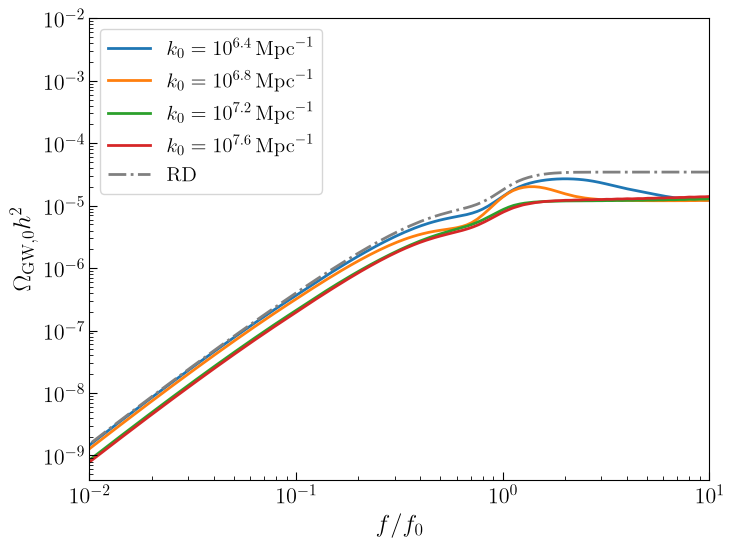

In [59]:
# Plot interpolated BPL spectra, parallel to the delta-spectrum plot.
if bpl_qcd_spectrum is not None:
    BPL_A_PLOT = 1.0
    # Plot the full cached scan range without the convergence-mask cut.
    bpl_plot_k0 = np.geomspace(10**6.4, 10**7.6, 4)
    x_bpl_plot = np.geomspace(1e-2, 1e2, 1000)
    fig, ax = plt.subplots(figsize=(8, 6))
    for k0 in bpl_plot_k0:
        omega_bpl_plot = S_BPL(x_bpl_plot, k0 / F_PEAK_TO_K_MPC, amplitude=BPL_A_PLOT)
        ax.loglog(x_bpl_plot, omega_bpl_plot,
                  label = rf'$k_0=10^{{{np.log10(k0):.1f}}}\,\mathrm{{Mpc}}^{{-1}}$')
    data = np.loadtxt('data/GW_ad_BPL.csv', delimiter=",", skiprows=1)
    kspan = data[:,0]
    OmegaGW =data[:,1]
    ax.plot(kspan*1e-6, OmegaGW, color='gray', ls='-.', label='RD')
    ax.set_xlabel(r'$f/f_0$')
    ax.set_ylabel(r'$\Omega_{\mathrm{GW},0}h^2$')
    #ax.axvline(10**7.2/10**7.6, ls=':', color='black')
    ax.legend()
    ax.set_xlim(1e-2, 1e1)
    ax.set_xlabel(r'$f/f_0$')
    ax.set_ylim(4e-10,1e-2)
    plt.savefig('../../../output/BPL_pure.pdf')
    plt.show()
else:
    print('BPL plot skipped: generate and load the scan first.')


## PTA model import check and adjustable spectra

The next cells import the exact model files used by PTArcade, rather than duplicating their formulas. They therefore check the complete path, units, normalization, IR/UV continuation, and amplitude dependence used in sampling. The model inputs are:

- delta: `log10_f_peak` [Hz] and `log10_A`;
- BPL: `log10_f0` [Hz] and `log10_A`.

Both functions return present-day $\Omega_{\rm GW,0}h^2$. The horizontal axis below is physical frequency $f$ [Hz]; the vertical dashed line marks the selected peak/turnover frequency.


In [38]:
# Import PTAcrade/qcd_delta.py and qcd_BPL.py exactly as PTArcade does.
import importlib.util
import sys
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

# Locate the project without requiring any expensive notebook cells first.
_candidates = [Path.cwd(), *Path.cwd().parents]
if 'PROJECT_DIR' in globals():
    _candidates.insert(0, Path(PROJECT_DIR).resolve())
PTA_MODEL_DIR = next((root / 'PTAcrade' for candidate in _candidates
                      for root in [candidate, *candidate.parents]
                      if (root / 'PTAcrade' / 'qcd_delta.py').exists()), None)
if PTA_MODEL_DIR is None:
    raise FileNotFoundError('Cannot locate PTAcrade/; run from the project directory.')

def _import_pta_model(filename, module_name):
    path = PTA_MODEL_DIR / filename
    if not path.exists():
        raise FileNotFoundError(f'PTA model file not found: {path}')
    if str(PTA_MODEL_DIR) not in sys.path:
        sys.path.insert(0, str(PTA_MODEL_DIR))
    spec = importlib.util.spec_from_file_location(module_name, path)
    module = importlib.util.module_from_spec(spec)
    spec.loader.exec_module(module)
    return module

pta_delta = _import_pta_model('qcd_delta.py', 'qcd_delta_notebook_check')
pta_bpl = _import_pta_model('qcd_BPL.py', 'qcd_bpl_notebook_check')
print('Imported:', pta_delta.__file__)
print('Imported:', pta_bpl.__file__)


Imported: C:\Research\92_real_IGW_at_PTA\PTAcrade\qcd_delta.py
Imported: C:\Research\92_real_IGW_at_PTA\PTAcrade\qcd_BPL.py


In [39]:
# Numerical consistency check at representative parameters.
CHECK_LOG10_F_PEAK = -8.0
CHECK_LOG10_F0 = -8.0
CHECK_LOG10_A = -1.0
CHECK_X = np.geomspace(1e-4, 1e3, 400)
CHECK_F_PEAK = 10.0**CHECK_LOG10_F_PEAK
CHECK_F0 = 10.0**CHECK_LOG10_F0

# Evaluate the exact PTArcade functions across IR, table and UV regions.
check_delta = pta_delta.spectrum(
    CHECK_X * CHECK_F_PEAK, CHECK_LOG10_F_PEAK, CHECK_LOG10_A
)
check_bpl = pta_bpl.spectrum(
    CHECK_X * CHECK_F0, CHECK_LOG10_F0, CHECK_LOG10_A
)
if not (np.all(np.isfinite(check_delta)) and np.all(check_delta >= 0)):
    raise RuntimeError('PTA delta model returned invalid values.')
if not (np.all(np.isfinite(check_bpl)) and np.all(check_bpl > 0)):
    raise RuntimeError('PTA BPL model returned invalid values.')

# Verify A^2 scaling, including the continuation regions.
check_delta_2 = pta_delta.spectrum(
    CHECK_X * CHECK_F_PEAK, CHECK_LOG10_F_PEAK, CHECK_LOG10_A + np.log10(2.0)
)
check_bpl_2 = pta_bpl.spectrum(
    CHECK_X * CHECK_F0, CHECK_LOG10_F0, CHECK_LOG10_A + np.log10(2.0)
)
np.testing.assert_allclose(check_delta_2, 4.0 * check_delta, rtol=2e-12, atol=0.0)
np.testing.assert_allclose(check_bpl_2, 4.0 * check_bpl, rtol=2e-12, atol=0.0)
print('PTA model check passed: finite spectra and exact A^2 scaling.')
delta_check_diagnostics = pta_delta.S(CHECK_X, CHECK_F_PEAK, True)[1]
bpl_check_diagnostics = pta_bpl.S(
    CHECK_X, CHECK_F0 * pta_bpl.MPC_INV_PER_HZ, True
)[1]
print('Delta: IR points =', np.count_nonzero(delta_check_diagnostics['infrared_continuation']),
      '; UV cutoff points =', np.count_nonzero(delta_check_diagnostics['outside_uv_support']))
print('BPL: IR points =', np.count_nonzero(bpl_check_diagnostics['used_ir_continuation']),
      '; UV points =', np.count_nonzero(bpl_check_diagnostics['used_uv_continuation']))

# Check broadcasting of parameters, as used by the PTArcade wrapper.
for module, log_peak in ((pta_delta, CHECK_LOG10_F_PEAK), (pta_bpl, CHECK_LOG10_F0)):
    frequencies = CHECK_X * 10.0**log_peak
    np.testing.assert_allclose(
        module.spectrum(frequencies, np.full(frequencies.shape, log_peak),
                        np.full(frequencies.shape, CHECK_LOG10_A)),
        module.spectrum(frequencies, log_peak, CHECK_LOG10_A), rtol=2e-12, atol=0.0,
    )
print('PTArcade array-parameter broadcasting passed.')


PTA model check passed: finite spectra and exact A^2 scaling.
Delta: IR points = 154 ; UV cutoff points = 154
BPL: IR points = 171 ; UV points = 57
PTArcade array-parameter broadcasting passed.


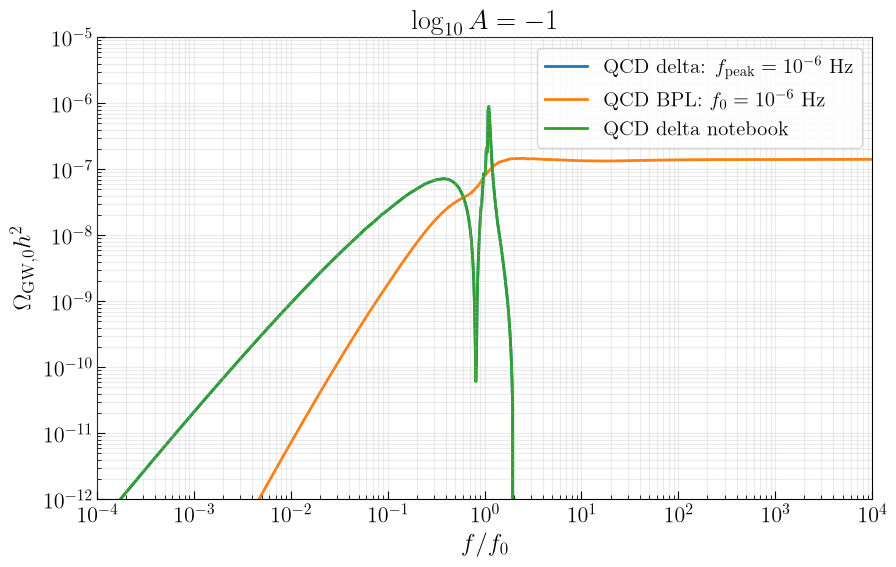

In [40]:
# Adjustable PTA spectra plot.
# Edit these parameters and rerun this cell; no scan is recomputed.
PLOT_LOG10_F_PEAK = -6.     # delta peak frequency [Hz]
PLOT_LOG10_F0 = PLOT_LOG10_F_PEAK     # BPL turnover frequency [Hz]
PLOT_LOG10_A = -1.0            # primordial amplitude log10(A)
PLOT_F_MIN = 1e-4              # plotted physical frequency [Hz]
PLOT_F_MAX = 1e4
PLOT_N_POINTS = 1200

frequency_plot = np.geomspace(PLOT_F_MIN*10.0**PLOT_LOG10_F_PEAK, PLOT_F_MAX*10.0**PLOT_LOG10_F_PEAK, int(PLOT_N_POINTS))
delta_plot = pta_delta.spectrum(frequency_plot, PLOT_LOG10_F_PEAK, PLOT_LOG10_A)
bpl_plot = pta_bpl.spectrum(frequency_plot, PLOT_LOG10_F0, PLOT_LOG10_A)

# Returned arrays remain available for further use, with frequency in Hz.
pta_spectrum_output = {
    'f_Hz': frequency_plot,
    'delta_OmegaGW_h2': delta_plot,
    'bpl_OmegaGW_h2': bpl_plot,
    'delta_parameters': dict(log10_f_peak=PLOT_LOG10_F_PEAK, log10_A=PLOT_LOG10_A),
    'bpl_parameters': dict(log10_f0=PLOT_LOG10_F0, log10_A=PLOT_LOG10_A),
}
if not (0 < PLOT_F_MIN < PLOT_F_MAX):
    raise ValueError('Require 0 < PLOT_F_MIN < PLOT_F_MAX.')
fig, ax = plt.subplots(figsize=(10, 6))
ax.loglog(frequency_plot/10.0**PLOT_LOG10_F_PEAK, delta_plot,
          label=fr'QCD delta: $f_\mathrm{{peak}}=10^{{{PLOT_LOG10_F_PEAK:g}}}$ Hz')
ax.loglog(frequency_plot/10.0**PLOT_LOG10_F0, bpl_plot,
          label=fr'QCD BPL: $f_0=10^{{{PLOT_LOG10_F0:g}}}$ Hz')
delta_diag = pta_delta.S(frequency_plot / 10.0**PLOT_LOG10_F_PEAK,
                        10.0**PLOT_LOG10_F_PEAK, True)[1]
bpl_diag = pta_bpl.S(frequency_plot / 10.0**PLOT_LOG10_F0,
                    10.0**PLOT_LOG10_F0 * pta_bpl.MPC_INV_PER_HZ, True)[1]

OmegaGW = S(frequency_plot/10.0**PLOT_LOG10_F_PEAK  , 10.0**PLOT_LOG10_F_PEAK)

ax.loglog(frequency_plot/10.0**PLOT_LOG10_F_PEAK, OmegaGW*1e-2,label='QCD delta notebook')

ax.axvline(10.0**PLOT_LOG10_F_PEAK, color='C0', ls=':', alpha=0.7)
ax.axvline(10.0**PLOT_LOG10_F0, color='C1', ls=':', alpha=0.7)
ax.set_xlabel(r'$f/f_0$')
ax.set_ylabel(r'$\Omega_{\mathrm{GW},0}h^2$')
ax.set_xlim(PLOT_F_MIN, PLOT_F_MAX)
ax.set_ylim(1e-12, 1e-5)
ax.set_title(fr'$\log_{{10}}A={PLOT_LOG10_A:g}$')
ax.grid(True, which='both', alpha=0.25)
ax.legend()
plt.show()


## PTA IR QCD tensor-transfer export
The PTA models use a tensor-only QCD/RD propagation ratio in the infrared, normalized to unity at each numerical-spectrum match point. The exporter below uses this notebook's high-temperature-calibrated thermal background and EoS, without recomputing the scalar, Green, or kernel caches. It is applied only when the scalar source ends before the QCD core; overlapping sources retain their numerical-spectrum normalization without an additional factor.


In [41]:
from export_qcd_ir_transfer import export_qcd_ir_transfer
# Reuse the saved table by default; set force=True to regenerate after background changes.
qcd_ir_transfer_path = export_qcd_ir_transfer(skip=True, force=False)
print(qcd_ir_transfer_path)


C:\Research\92_real_IGW_at_PTA\sigw\SIGW_EOS\SIGW_EOS\data\qcd_ir_tensor_transfer.csv
